In [1]:
# %matplotlib widget

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.gridspec as gridspec
from matplotlib.gridspec import GridSpec,GridSpecFromSubplotSpec
from matplotlib import animation, rc
from mpl_toolkits.axes_grid1 import make_axes_locatable
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d import axes3d

from sklearn.cluster import OPTICS, cluster_optics_dbscan

from astropy.table import Table
import astropy.units as u
import astropy.constants as const
import corner

from tqdm.notebook import trange, tqdm
import re
import warnings
import os
import importlib
import VarStar_Vi_plot_functions as vi
from subprocess import *

In [2]:
# data = Table.read("/Users/benjaminroulston/Dropbox/Research/TDSS/Variable_Stars/HARD_COPY_ORGINAL_DATA/PROGRAM_SAMPLE/2021-07-27/FINAL_FILES/TDSS_SES+PREV_DR16DR12griLT20_GaiaEDR3_Drake2014PerVar_CSSID_ZTFIDs_LCpointer_PyHammer_EqW_LCProps.fits")
# data = Table.read('/Users/benjaminroulston/Dropbox/Research/TDSS/Variable_Stars/WORKING_DIRECTORY/Statistical_Testing/LC_stat_calculations/Control_StatsCalc/TDSS_VarStar_FINAL_Var_ALL_PROP_STATS_03-15-2022.fits')
data = Table.read("/Users/benjaminroulston/Dropbox/Research/Manuscripts/tdss-varstar-paper/src/data/TDSS_VarStar_FINAL_Var_ALL_PROP_STATS_dealiased.fits")
data.add_column(np.arange(len(data)), index=0, name='prop_id')

# full_index_table = Table.read("/Users/benjaminroulston/Dropbox/Research/TDSS/Variable_Stars/WORKING_DIRECTORY/Statistical_Testing/LC_stat_calculations/Control_StatsCalc/full_index_table.fits")
def translate_propid_full_to_var(var_prop_id, full_index_table):
    """translate_propid_full_to_var(var_prop_id, full_index_table)

    Translate the prop_id of a row in the selected variables table back into the full sample prop_id.

    Parameters
    ----------
    var_prop_id : integer
        prop_id of the star in the selected variables table
    full_index_table : astropy table
        Table which containes the index array for the selected variables.

    Returns
    -------
    prop_id : integer
        prop_id of the star in the full VarStar sample table, indexed on 0.

    Warnings
    --------
    The returned prop_id matches the full VarStar selected table, and is 0 indexed. 
    The output LC plots however are 1 indexed, so if trying to look up a plot, +1
    """
    return np.where(full_index_table['cumsum']==var_prop_id)[0][0]

def SplitSingleSpecType(spectype):
    spectype_letters = np.array(['O', 'B', 'A', 'F', 'G', 'K', 'M', 'L', 'dC', 'DA'])
    if 'DA' in spectype:
        maintype = 9.0
        subtype = np.float64(re.split('(\d.*)', spectype)[1]) / 10.0
    elif 'dC' in spectype:
        maintype = 8.0
        subtype = np.where(np.array(['G', 'K', 'M']) == spectype[-1])[0][0] / 10.0
    else:
        maintype = np.where(spectype_letters == spectype[0])[0][0]
        subtype = np.float64(spectype[1]) / 10.0
    
    return maintype + subtype


def SplitSpecType(spectype):
    spectype_letters = np.array(['O', 'B', 'A', 'F', 'G', 'K', 'M', 'L', 'dC', 'DA'])
    if '+' in spectype:
        spectype1, spectype2 = spectype.replace("+", " ").split()
        return SplitSingleSpecType(spectype1), SplitSingleSpecType(spectype2)
    else:
        return SplitSingleSpecType(spectype), 99.0

# re.split('(\d.*)', data['PyHammerSpecType'][136])
print(data['PyHammerSpecType'][427], SplitSpecType(data['PyHammerSpecType'][427]))
print(data['PyHammerSpecType'][136], SplitSpecType(data['PyHammerSpecType'][136]))

# for spectype in data['PyHammerSpecType']:
#     print(SplitSpecType(spectype))


# for ii, spectype in enumerate(data['PyHammerSpecType']):
#     if "+" not in spectype and "dC" in spectype:
#         print(ii)
        
# print(data['PyHammerSpecType'][427])

# data['PyHammerSpecType']

all_spectype1 = np.zeros(len(data)) * np.nan
all_spectype2 = np.zeros(len(data)) * np.nan

for ii, spectype in enumerate(data['PyHammerSpecType']):
    #print(ii, spectype, SplitSpecType(spectype))
    all_spectype1[ii], all_spectype2[ii] = SplitSpecType(spectype)

print(all_spectype1)
print(all_spectype2)

pyhammer_spectype_index = data.index_column('PyHammerSpecType')

data.add_column(all_spectype1, index=pyhammer_spectype_index+1, name='PyHammerSpecType1')
data.add_column(all_spectype2, index=pyhammer_spectype_index+2, name='PyHammerSpecType2')


M_G = data['phot_g_mean_mag'] + 5 - 5*np.log10(data['rpgeo'])
MG_index = data.index_column('B_rpgeo_GaiaEDR3a')
data.add_column(M_G, index=MG_index+1, name='M_G')


pos_steps = np.arange(3.0, 10.25, 0.25)
pos_step_colnames_g = [f'ZTF_g_sigma{ss}' for ss in pos_steps]
pos_step_colnames_r = [f'ZTF_r_sigma{ss}' for ss in pos_steps]

neg_step_colnames_g = [f'ZTF_g_sigma{-ss}' for ss in pos_steps]
neg_step_colnames_r = [f'ZTF_r_sigma{-ss}' for ss in pos_steps]

sum_g_Nabove3sigma = data[pos_step_colnames_g].to_pandas().sum(axis=1).to_numpy()
sum_r_Nabove3sigma = data[pos_step_colnames_r].to_pandas().sum(axis=1).to_numpy()

sum_g_Nbelow3sigma = data[neg_step_colnames_g].to_pandas().sum(axis=1).to_numpy()
sum_r_Nbelow3sigma = data[neg_step_colnames_r].to_pandas().sum(axis=1).to_numpy()

data_panda = data.to_pandas()

mean_g_Nabove3sigma = np.zeros(len(data)) * np.nan
mean_r_Nabove3sigma = np.zeros(len(data)) * np.nan
mean_g_Nbelow3sigma = np.zeros(len(data)) * np.nan
mean_r_Nbelow3sigma = np.zeros(len(data)) * np.nan
total_mean_g = np.zeros(len(data)) * np.nan
total_mean_r = np.zeros(len(data)) * np.nan

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for ii in trange(len(data)):
        method_count1 = (np.diff(np.append(data_panda[pos_step_colnames_g].to_numpy()[ii, :], 0))*-1)
        mean_g_Nabove3sigma[ii] = np.nansum(method_count1 * pos_steps) / np.nansum(method_count1)

        method_count2 = (np.diff(np.append(data_panda[pos_step_colnames_r].to_numpy()[ii, :], 0))*-1)
        mean_r_Nabove3sigma[ii] = np.nansum(method_count2 * pos_steps) / np.nansum(method_count2)

        method_count3 = (np.diff(np.append(data_panda[neg_step_colnames_g].to_numpy()[ii, :], 0))*-1)
        mean_g_Nbelow3sigma[ii] = np.nansum(method_count3 * -pos_steps) / np.nansum(method_count3)

        method_count4 = (np.diff(np.append(data_panda[neg_step_colnames_r].to_numpy()[ii, :], 0))*-1)
        mean_r_Nbelow3sigma[ii] = np.nansum(method_count4 * -pos_steps) / np.nansum(method_count4)
        
        total_mean_g[ii] = (np.nansum(method_count1 * pos_steps) + np.nansum(method_count3 * -pos_steps)) / (np.nansum(method_count1) + np.nansum(method_count3))
        total_mean_r[ii] = (np.nansum(method_count2 * pos_steps) + np.nansum(method_count4 * -pos_steps)) / (np.nansum(method_count2) + np.nansum(method_count4))
    


data.add_column(sum_g_Nabove3sigma, name='ZTF_g_Nabove3sigma')
data.add_column(sum_g_Nbelow3sigma, name='ZTF_g_Nbelow3sigma')
data.add_column(total_mean_g, name='ZTF_g_N3sigma')

data.add_column(sum_r_Nabove3sigma, name='ZTF_r_Nabove3sigma')
data.add_column(sum_r_Nbelow3sigma, name='ZTF_r_Nbelow3sigma')
data.add_column(total_mean_r, name='ZTF_r_N3sigma')


# data

M5+DA5.0 (6.5, 9.5)
F1 (3.1, 99.0)
[3.4 6.1 6.5 ... 6.5 6.  6.3]
[99.    9.35 99.   ... 99.   99.    9.7 ]


  0%|          | 0/11861 [00:00<?, ?it/s]

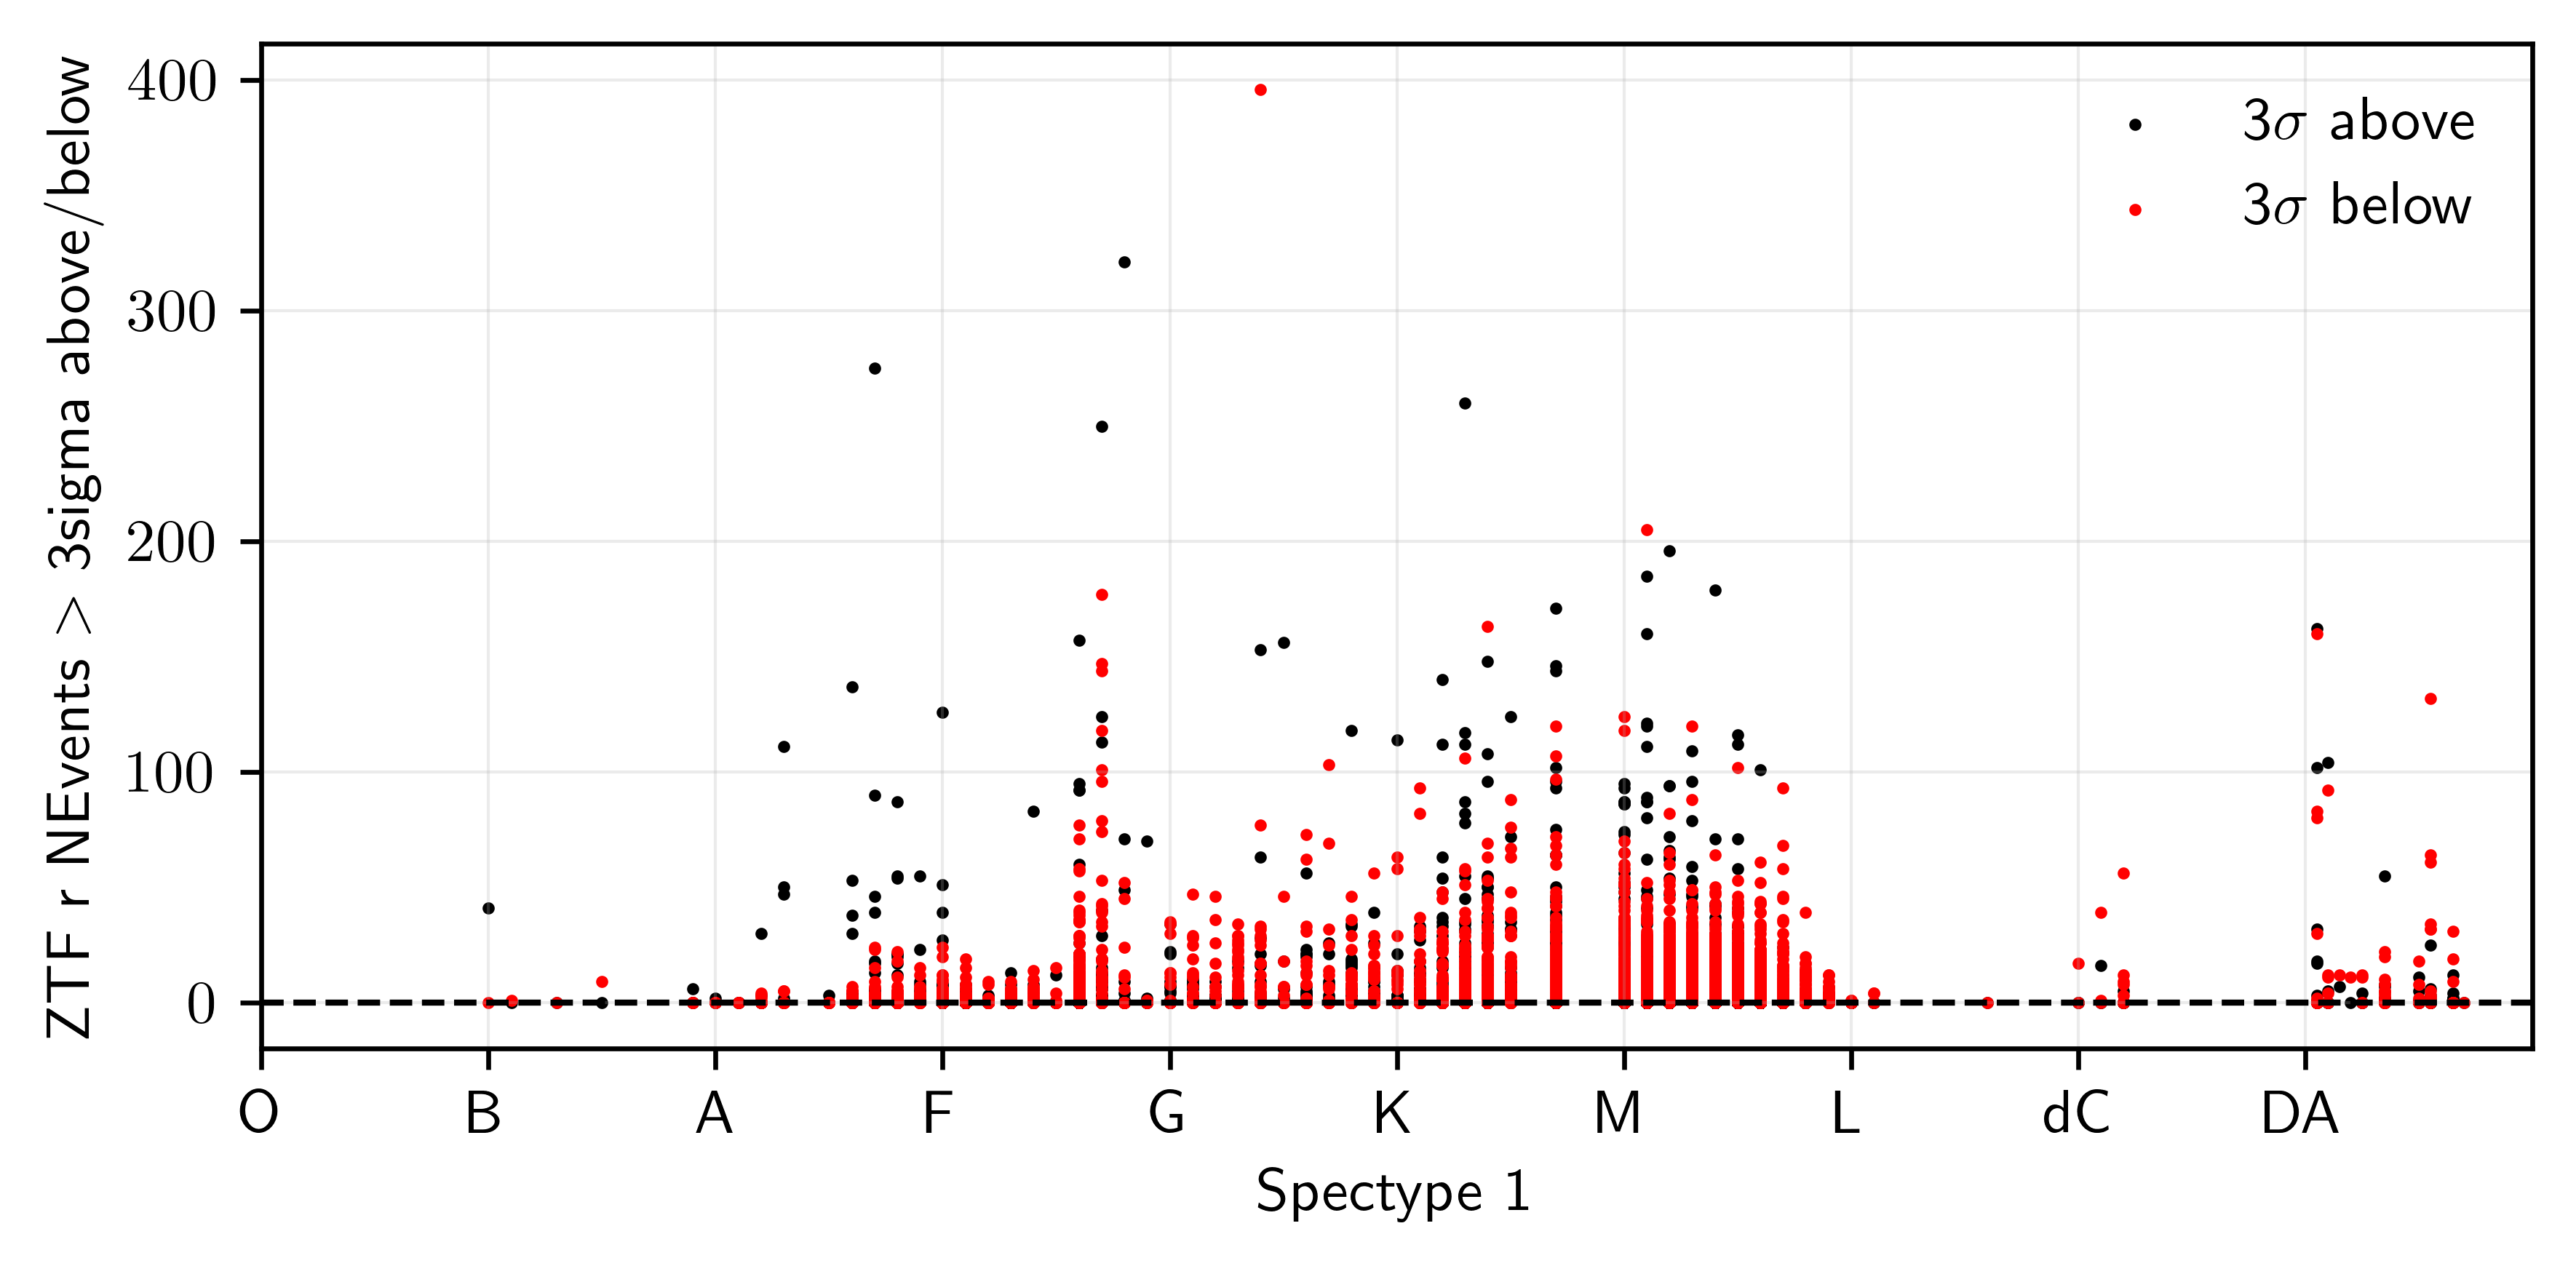

In [8]:
fig = plt.figure(figsize=(6,3), dpi=600) 
ax = plt.gca()
# ax.scatter(data['PyHammerSpecType1'], data['ZTF_r_N3sigma'], s=1, c='k')

ax.scatter(data['PyHammerSpecType1'], data['ZTF_r_Nabove3sigma'], s=1, c='k', label='3$\sigma$ above')
ax.scatter(data['PyHammerSpecType1'], data['ZTF_r_Nbelow3sigma'], s=1, c='r', label='3$\sigma$ below')


ax.set_xlabel('Spectype 1')
# ax.set_ylabel('ZTF r mean 3sigma above/below')
ax.set_ylabel('ZTF r NEvents $>$ 3sigma above/below')


ax.set_xlim(0,10)

ax.xaxis.set_major_locator(ticker.FixedLocator(np.arange(10)))
# ax.xaxis.set_minor_locator(ticker.MultipleLocator(0.2))

# ax.yaxis.set_major_locator(ticker.MultipleLocator(2.5))
# ax.yaxis.set_minor_locator(ticker.MultipleLocator(0.25))

spectype_letters = np.array(['O', 'B', 'A', 'F', 'G', 'K', 'M', 'L', 'dC', 'DA'])
ax.set_xticklabels(spectype_letters)

ax.axhline(0.0, c='k', lw=1.0, ls='dashed')
ax.grid(alpha=0.25, lw=0.5)

plt.legend(loc='best', frameon=False)
plt.tight_layout()
plt.savefig("/Users/benjaminroulston/Dropbox/Research/Projects/Variable_Stars/WORKING_DIRECTORY/Classification/VarStar_r_meanALL3sigma.pdf", dpi=600, bbox_inches='tight', facecolor='white')
plt.savefig("/Users/benjaminroulston/Dropbox/Research/Projects/Variable_Stars/WORKING_DIRECTORY/Classification/VarStar_r_meanALL3sigma.png", dpi=600, bbox_inches='tight', facecolor='white')

In [9]:
selection_index = ((data['ZTF_g_logProb'] <= -5.0).data | (data['ZTF_r_logProb'] <= -5.0).data) & \
                  (((data['ZTF_r_P'] <= 100.0).data & (data['ZTF_g_P'] <= 100.0).data)) & data['isDrake']
# selection_index = (data['ZTF_r_P'] <= 10.0).data


# selected_data = data[selection_index][['bp_rp', 'ZTF_r_P', 'ZTF_r_a95', 'ZTF_r_lc_skew', 'ZTF_r_Mt', 'ZTF_r_Amp', 'ZTF_r_VarStat']]
# selected_data = data[selection_index][['bp_rp', 'M_G', 'ZTF_r_P', 'ZTF_r_a95', 'ZTF_r_lc_skew', 'ZTF_r_Mt', 'ZTF_r_Amp', 'PyHammerSpecType1', 'PyHammerSpecType2']]
# selected_data = data[selection_index][['bp_rp', 'ZTF_r_P', 'ZTF_r_lc_skew', 'ZTF_r_Mt', 'ZTF_r_Amp', 'PyHammerSpecType1']]


# selection_colnames = ['bp_rp', 'M_G', 'PyHammerSpecType1', 'PyHammerSpecType2', 'W_Halpha', 'W_Halpha_error', 'ZTF_g_P', 'ZTF_g_Amp', 'ZTF_g_Mt', 'ZTF_g_a95', 'ZTF_g_lc_skew', 'ZTF_g_Chi2', 'ZTF_g_nabove', 'ZTF_g_nbelow', 'ZTF_g_VarStat', 'ZTF_g_Con', 'ZTF_g_m', 'ZTF_g_b_lin', 'ZTF_g_chi2_lin', 'ZTF_g_a', 'ZTF_g_b_quad', 'ZTF_g_c', 'ZTF_g_chi2_quad', 'ZTF_g_std', 'ZTF_g_weighted_std', 'ZTF_g_skewness', 'ZTF_g_kurtosis', 'ZTF_g_shapiro_w', 'ZTF_g_quartile31', 'ZTF_g_stetson_j', 'ZTF_g_stetson_k', 'ZTF_g_stetson_l', 'ZTF_g_eta', 'ZTF_g_cumsum', 'ZTF_g_half_mag_amplitude_ratio', 'ZTF_g_alarm', 'ZTF_r_P', 'ZTF_r_Amp', 'ZTF_r_Mt', 'ZTF_r_a95', 'ZTF_r_lc_skew', 'ZTF_r_Chi2', 'ZTF_r_nabove', 'ZTF_r_nbelow', 'ZTF_r_VarStat', 'ZTF_r_Con', 'ZTF_r_m', 'ZTF_r_b_lin', 'ZTF_r_chi2_lin', 'ZTF_r_a', 'ZTF_r_b_quad', 'ZTF_r_c', 'ZTF_r_chi2_quad', 'ZTF_r_std', 'ZTF_r_weighted_std', 'ZTF_r_skewness', 'ZTF_r_kurtosis', 'ZTF_r_shapiro_w', 'ZTF_r_quartile31', 'ZTF_r_stetson_j', 'ZTF_r_stetson_k', 'ZTF_r_stetson_l', 'ZTF_r_eta', 'ZTF_r_cumsum', 'ZTF_r_half_mag_amplitude_ratio', 'ZTF_r_alarm', 'ZTF_g_Nabove3sigma', 'ZTF_g_Nbelow3sigma', 'ZTF_g_N3sigma', 'ZTF_r_Nabove3sigma', 'ZTF_r_Nbelow3sigma', 'ZTF_r_N3sigma']
selection_colnames = ['bp_rp', 'M_G', 'PyHammerSpecType1', 'PyHammerSpecType2', 'W_Halpha', 'W_Halpha_error', 'ZTF_r_P', 'ZTF_r_Amp', 'ZTF_r_Mt', 'ZTF_r_a95', 'ZTF_r_lc_skew', 'ZTF_r_Chi2', 'ZTF_r_nabove', 'ZTF_r_nbelow', 'ZTF_r_VarStat', 'ZTF_r_Con', 'ZTF_r_m', 'ZTF_r_b_lin', 'ZTF_r_chi2_lin', 'ZTF_r_a', 'ZTF_r_b_quad', 'ZTF_r_c', 'ZTF_r_chi2_quad', 'ZTF_r_std', 'ZTF_r_weighted_std', 'ZTF_r_skewness', 'ZTF_r_kurtosis', 'ZTF_r_shapiro_w', 'ZTF_r_quartile31', 'ZTF_r_stetson_j', 'ZTF_r_stetson_k', 'ZTF_r_stetson_l', 'ZTF_r_eta', 'ZTF_r_cumsum', 'ZTF_r_half_mag_amplitude_ratio', 'ZTF_r_alarm', 'ZTF_r_Nabove3sigma', 'ZTF_r_Nbelow3sigma', 'ZTF_r_N3sigma']

selected_data =  data[selection_index][selection_colnames]

nonP_selection_colnames = ['bp_rp', 'M_G', 'PyHammerSpecType1', 'PyHammerSpecType2', 'W_Halpha', 'W_Halpha_error', 'ZTF_g_Mt', 'ZTF_g_a95', 'ZTF_g_lc_skew', 'ZTF_g_Chi2', 'ZTF_g_nabove', 'ZTF_g_nbelow', 'ZTF_g_VarStat', 'ZTF_g_Con', 'ZTF_g_m', 'ZTF_g_b_lin', 'ZTF_g_chi2_lin', 'ZTF_g_a', 'ZTF_g_b_quad', 'ZTF_g_c', 'ZTF_g_chi2_quad', 'ZTF_g_std', 'ZTF_g_weighted_std', 'ZTF_g_skewness', 'ZTF_g_kurtosis', 'ZTF_g_shapiro_w', 'ZTF_g_quartile31', 'ZTF_g_stetson_j', 'ZTF_g_stetson_k', 'ZTF_g_stetson_l', 'ZTF_g_eta', 'ZTF_g_cumsum', 'ZTF_g_half_mag_amplitude_ratio', 'ZTF_g_alarm', 'ZTF_r_Mt', 'ZTF_r_a95', 'ZTF_r_lc_skew', 'ZTF_r_Chi2', 'ZTF_r_nabove', 'ZTF_r_nbelow', 'ZTF_r_VarStat', 'ZTF_r_Con', 'ZTF_r_m', 'ZTF_r_b_lin', 'ZTF_r_chi2_lin', 'ZTF_r_a', 'ZTF_r_b_quad', 'ZTF_r_c', 'ZTF_r_chi2_quad', 'ZTF_r_std', 'ZTF_r_weighted_std', 'ZTF_r_skewness', 'ZTF_r_kurtosis', 'ZTF_r_shapiro_w', 'ZTF_r_quartile31', 'ZTF_r_stetson_j', 'ZTF_r_stetson_k', 'ZTF_r_stetson_l', 'ZTF_r_eta', 'ZTF_r_cumsum', 'ZTF_r_half_mag_amplitude_ratio', 'ZTF_r_alarm', 'ZTF_g_Nabove3sigma', 'ZTF_g_Nbelow3sigma', 'ZTF_g_N3sigma', 'ZTF_r_Nabove3sigma', 'ZTF_r_Nbelow3sigma', 'ZTF_r_N3sigma']
nonP_selected_data =  data[~selection_index][nonP_selection_colnames]

selected_data

bp_rp,M_G,PyHammerSpecType1,PyHammerSpecType2,W_Halpha,W_Halpha_error,ZTF_r_P,ZTF_r_Amp,ZTF_r_Mt,ZTF_r_a95,ZTF_r_lc_skew,ZTF_r_Chi2,ZTF_r_nabove,ZTF_r_nbelow,ZTF_r_VarStat,ZTF_r_Con,ZTF_r_m,ZTF_r_b_lin,ZTF_r_chi2_lin,ZTF_r_a,ZTF_r_b_quad,ZTF_r_c,ZTF_r_chi2_quad,ZTF_r_std,ZTF_r_weighted_std,ZTF_r_skewness,ZTF_r_kurtosis,ZTF_r_shapiro_w,ZTF_r_quartile31,ZTF_r_stetson_j,ZTF_r_stetson_k,ZTF_r_stetson_l,ZTF_r_eta,ZTF_r_cumsum,ZTF_r_half_mag_amplitude_ratio,ZTF_r_alarm,ZTF_r_Nabove3sigma,ZTF_r_Nbelow3sigma,ZTF_r_N3sigma
mag,mag,,,Angstrom,Angstrom,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
1.208454,6.170908507655152,5.3,99.0,--,--,0.5628982505122374,0.4714261919831806,0.844685971736908,0.4792954444885247,2.3321834656371556,18.502443028446844,135.0,49.0,5.2068610191345215,0.0,2.096191127323936e-05,17.958399682901067,17.833518803279645,-1.3302091834036188e-07,0.00014456062601229505,17.941017978740778,17.698670688174865,0.15738665497331444,0.12156745703257585,2.4729198836548765,6.0200963954266395,0.6602877378463745,0.06663217981978775,2.872449898292146,0.6499331337049861,2.3394741401097527,2.109736408170607,0.22821202839223217,3.3051141339828725,-0.5227205238181416,34.0,0.0,3.4038461538461537
1.304153,6.792426977161345,5.4,99.0,--,--,0.25837389803532484,0.6593035726456584,0.7166611552238464,0.6979467391967802,0.7927830874526711,7.2290706417283594,122.0,105.0,2.7609643936157227,0.0136986301369863,8.727409641515154e-05,19.16432070869312,6.454538066684302,-2.8451815542506838e-08,0.0001127715913710707,19.160994352675893,6.453752653365279,0.21503450497323862,0.19078514095116544,0.7589876800033897,-0.201030189450087,0.9311001896858215,0.29403878379256554,2.105990371516164,0.8138816697610458,2.1479034587346626,1.7655181204944936,0.31054523532036366,1.3437350874687468,0.8107347302089294,1.0,0.0,3.0
1.332438,6.48118476858949,5.5,99.0,--,--,0.21644272059842082,0.3953461707237196,0.6555086970329285,0.38191108703612997,0.7396593379368058,17.066382647280967,135.0,90.0,4.241876602172852,0.00909090909090909,-3.9083593346441836e-05,17.996420270842613,16.60645597944577,6.016288026742493e-08,-9.554200594619482e-05,18.00472366449258,16.579270382092243,0.11884579018531531,0.11238366923837398,0.7653031945096013,-0.3277093316467239,0.9273815751075745,0.15807586741638247,3.3706804266656527,0.827435289602934,3.4950124498709716,2.185486632547147,0.15625034745466315,1.3889315633353503,-0.11008029739678449,0.0,0.0,nan
0.506968,2.9069881665494783,3.3,99.0,2.848608113050922,0.15175014861941696,0.387116754413131,0.31607027645746655,0.3618885576725006,0.46533031463622976,-0.5836680511159422,36.21317570846273,51.0,66.0,5.681385517120361,0.0,2.1290218543230633e-05,17.443953375293468,35.388727193827265,-1.133176954697221e-07,0.00012906264657130858,17.429899208644382,35.26813122911316,0.1388252644133952,0.14291673955744855,-0.4167628483379613,-0.2523390495301543,0.9794028997421265,0.17801583323168657,4.868517694498609,0.7959836879482985,4.856216377579637,2.013865492076477,0.18570157786709135,0.7408782415122773,-0.1110061879126083,0.0,0.0,nan
0.526495,5.889838783548143,2.8,99.0,1.9451436288177257,0.37430610728394587,0.3006072265977274,0.4481026284346541,0.5663632154464722,0.45212507247924805,0.14644746378382673,37.62487109375,59.0,53.0,6.0848541259765625,0.0,-1.1175535228833404e-05,17.86297977234993,36.194383816113096,-1.2730091229086565e-06,0.0005711871462044404,17.84765337763569,35.92846849975058,0.161072697001551,0.15665666822183147,0.11892188972503463,-1.4502419995295903,0.9176275730133057,0.30079573554484895,5.476707005938265,0.9132981343550606,6.268002870842991,2.1633247924758385,0.21483871060646012,0.9832036638015617,0.07898320140692894,0.0,0.0,nan
1.363409,6.88198975

In [10]:
def make_X_astroTable(table):
    hold = []
    for col in table.colnames:
        if hasattr(table[col].data, 'mask'):
            if col=='ZTF_r_logProb':
                col_hold = np.array(table[col].data.data.tolist())
                col_hold[np.where(~np.isfinite(col_hold))[0]] = 0.0
                hold.append(col_hold.tolist())
            else:
                hold.append(table[col].data.data.tolist())
        else:
            hold.append(table[col].data.tolist())
    return np.array(hold).T


X = make_X_astroTable(selected_data)
# X = make_X_astroTable(nonP_selected_data)

######################################################################
######################################################################
######################################################################
######################################################################

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
imp = IterativeImputer(max_iter=10, random_state=0)
imp.fit(X)

X = imp.transform(X)

######################################################################
######################################################################
######################################################################
######################################################################

from sklearn import preprocessing
scaler = preprocessing.StandardScaler().fit(X)
X_scaled = scaler.transform(X)

######################################################################
######################################################################
######################################################################
######################################################################
from sklearn.decomposition import PCA
pca = PCA(n_components=10)
pca.fit(X_scaled)

print("PCA explained variance ratio:", pca.explained_variance_ratio_)
print("PCA explained variance ratio CDF:", np.cumsum(pca.explained_variance_ratio_))
# print(pca.singular_values_)

pca_X = pca.transform(X_scaled)

######################################################################
######################################################################
######################################################################
######################################################################

# from sklearn.cluster import AgglomerativeClustering
# clustering = AgglomerativeClustering(n_clusters=10).fit(X)
# print("######################################################################")
# print("AgglomerativeClustering")
# print(np.unique(clustering.labels_, return_counts=True))

######################################################################

from sklearn.cluster import KMeans
clustering = KMeans(n_clusters=17, n_init=100, max_iter=1000, algorithm='full').fit(X_scaled)
print("######################################################################")
print("KMeans")
print(np.unique(clustering.labels_, return_counts=True))

######################################################################

# from sklearn.cluster import MeanShift
# clustering = MeanShift(bandwidth=10, cluster_all=False, n_jobs=4).fit(X_scaled)
# print("######################################################################")
# print("MeanShift")
# print(np.unique(clustering.labels_, return_counts=True))

######################################################################

# import hdbscan
# clusterer = hdbscan.HDBSCAN(min_cluster_size=5,
#                             min_samples=None,
#                             metric='euclidean',
#                             alpha=1.0,
#                             cluster_selection_epsilon=0.0,
#                             algorithm='best',
#                             leaf_size=40,
#                             approx_min_span_tree=True,
#                             gen_min_span_tree=False,
#                             core_dist_n_jobs=4,
#                             cluster_selection_method='eom',
#                             allow_single_cluster=False,
#                             prediction_data=False,
#                             match_reference_implementation=False)
# clusterer.fit(X_scaled)
# clustering = clusterer
# print("######################################################################")
# print("hdbscan")
# print(np.unique(clustering.labels_, return_counts=True))



PCA explained variance ratio: [0.21498051 0.20635318 0.13831399 0.06288198 0.04780133 0.04632101
 0.04056033 0.0375758  0.02779772 0.02665347]
PCA explained variance ratio CDF: [0.21498051 0.42133368 0.55964767 0.62252965 0.67033098 0.71665199
 0.75721232 0.79478812 0.82258584 0.84923931]


/Users/benjaminroulston/Dropbox/Research/Coding/PYTHON3_ENVS/Research/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:1366: FutureWarning: algorithm='full' is deprecated, it will be removed in 1.3. Using 'lloyd' instead.
  warnings.warn(


######################################################################
KMeans
(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16],
      dtype=int32), array([ 12,  78,  81,  95,  28,  67,   2,  41,  18,  33, 126,  60,   5,
         3, 154,  70,   1]))


In [12]:
# jjj=0

In [14]:
def make_ML_dirs(cluster_names, test_dir_name='temp_test', ml_dir="/Users/benjaminroulston/Dropbox/Research/Projects/Variable_Stars/WORKING_DIRECTORY/Classification/Unsupervised/"):
    datestr = check_output(["/bin/date","+%F"])
    datestr = datestr.decode().replace('\n', '')
    if not os.path.exists(ml_dir+datestr):
        os.mkdir(ml_dir+datestr)

    test_dir = ml_dir + datestr + f"/{test_dir_name}/"
    if not os.path.exists(test_dir):
        os.mkdir(test_dir)
    
    cluster_dirs = []
    for this_clust_name in cluster_names:
        hold_dir = test_dir + f"{this_clust_name}/"
        cluster_dirs.append(hold_dir)
        if not os.path.exists(hold_dir):
            os.mkdir(hold_dir)
        
    return cluster_dirs, test_dir, datestr


def send_Vi_panel_clusters(all_cluster_labels, TDSS_Table, Vi_datestr, test_dir_name='temp_test', ml_dir="/Users/benjaminroulston/Dropbox/Research/Projects/Variable_Stars/WORKING_DIRECTORY/Classification/Unsupervised/"):
    cluster_names = np.unique(all_cluster_labels)
    cluster_dirs, test_dir, ML_datestr = make_ML_dirs(cluster_names, test_dir_name=test_dir_name, ml_dir=ml_dir)
    
    for ii in range(cluster_names.size):
        this_cluster = cluster_names[ii]
        if this_cluster!=3:
            cluster_indexs = np.where(all_cluster_labels==this_cluster)[0]
            vi.get_Vi_panels(cluster_indexs, TDSS_Table, Vi_datestr, copy=True, moveDir=cluster_dirs[ii])
        print(f"Cluster {this_cluster} has been moved.")
    
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=UserWarning)
    send_Vi_panel_clusters(clustering.labels_, data[selection_index], '2023-03-24', test_dir_name=f'temp_test_{jjj}', ml_dir="/Users/benjaminroulston/Dropbox/Research/Projects/Variable_Stars/WORKING_DIRECTORY/Classification/Unsupervised/")
    jjj += 1

12it [00:00, 147.04it/s]


Cluster 0 has been moved.


78it [00:00, 112.43it/s]


Cluster 1 has been moved.


81it [00:00, 96.94it/s] 


Cluster 2 has been moved.
Cluster 3 has been moved.


28it [00:00, 103.46it/s]


Cluster 4 has been moved.


67it [00:00, 135.54it/s]


Cluster 5 has been moved.


2it [00:00, 113.00it/s]


Cluster 6 has been moved.


41it [00:00, 137.19it/s]


Cluster 7 has been moved.


18it [00:00, 155.27it/s]


Cluster 8 has been moved.


33it [00:00, 174.73it/s]


Cluster 9 has been moved.


126it [00:01, 116.18it/s]


Cluster 10 has been moved.


60it [00:00, 129.85it/s]


Cluster 11 has been moved.


5it [00:00, 141.92it/s]


Cluster 12 has been moved.


3it [00:00, 169.12it/s]


Cluster 13 has been moved.


154it [00:01, 125.95it/s]


Cluster 14 has been moved.


70it [00:00, 144.01it/s]


Cluster 15 has been moved.


1it [00:00, 193.35it/s]

Cluster 16 has been moved.


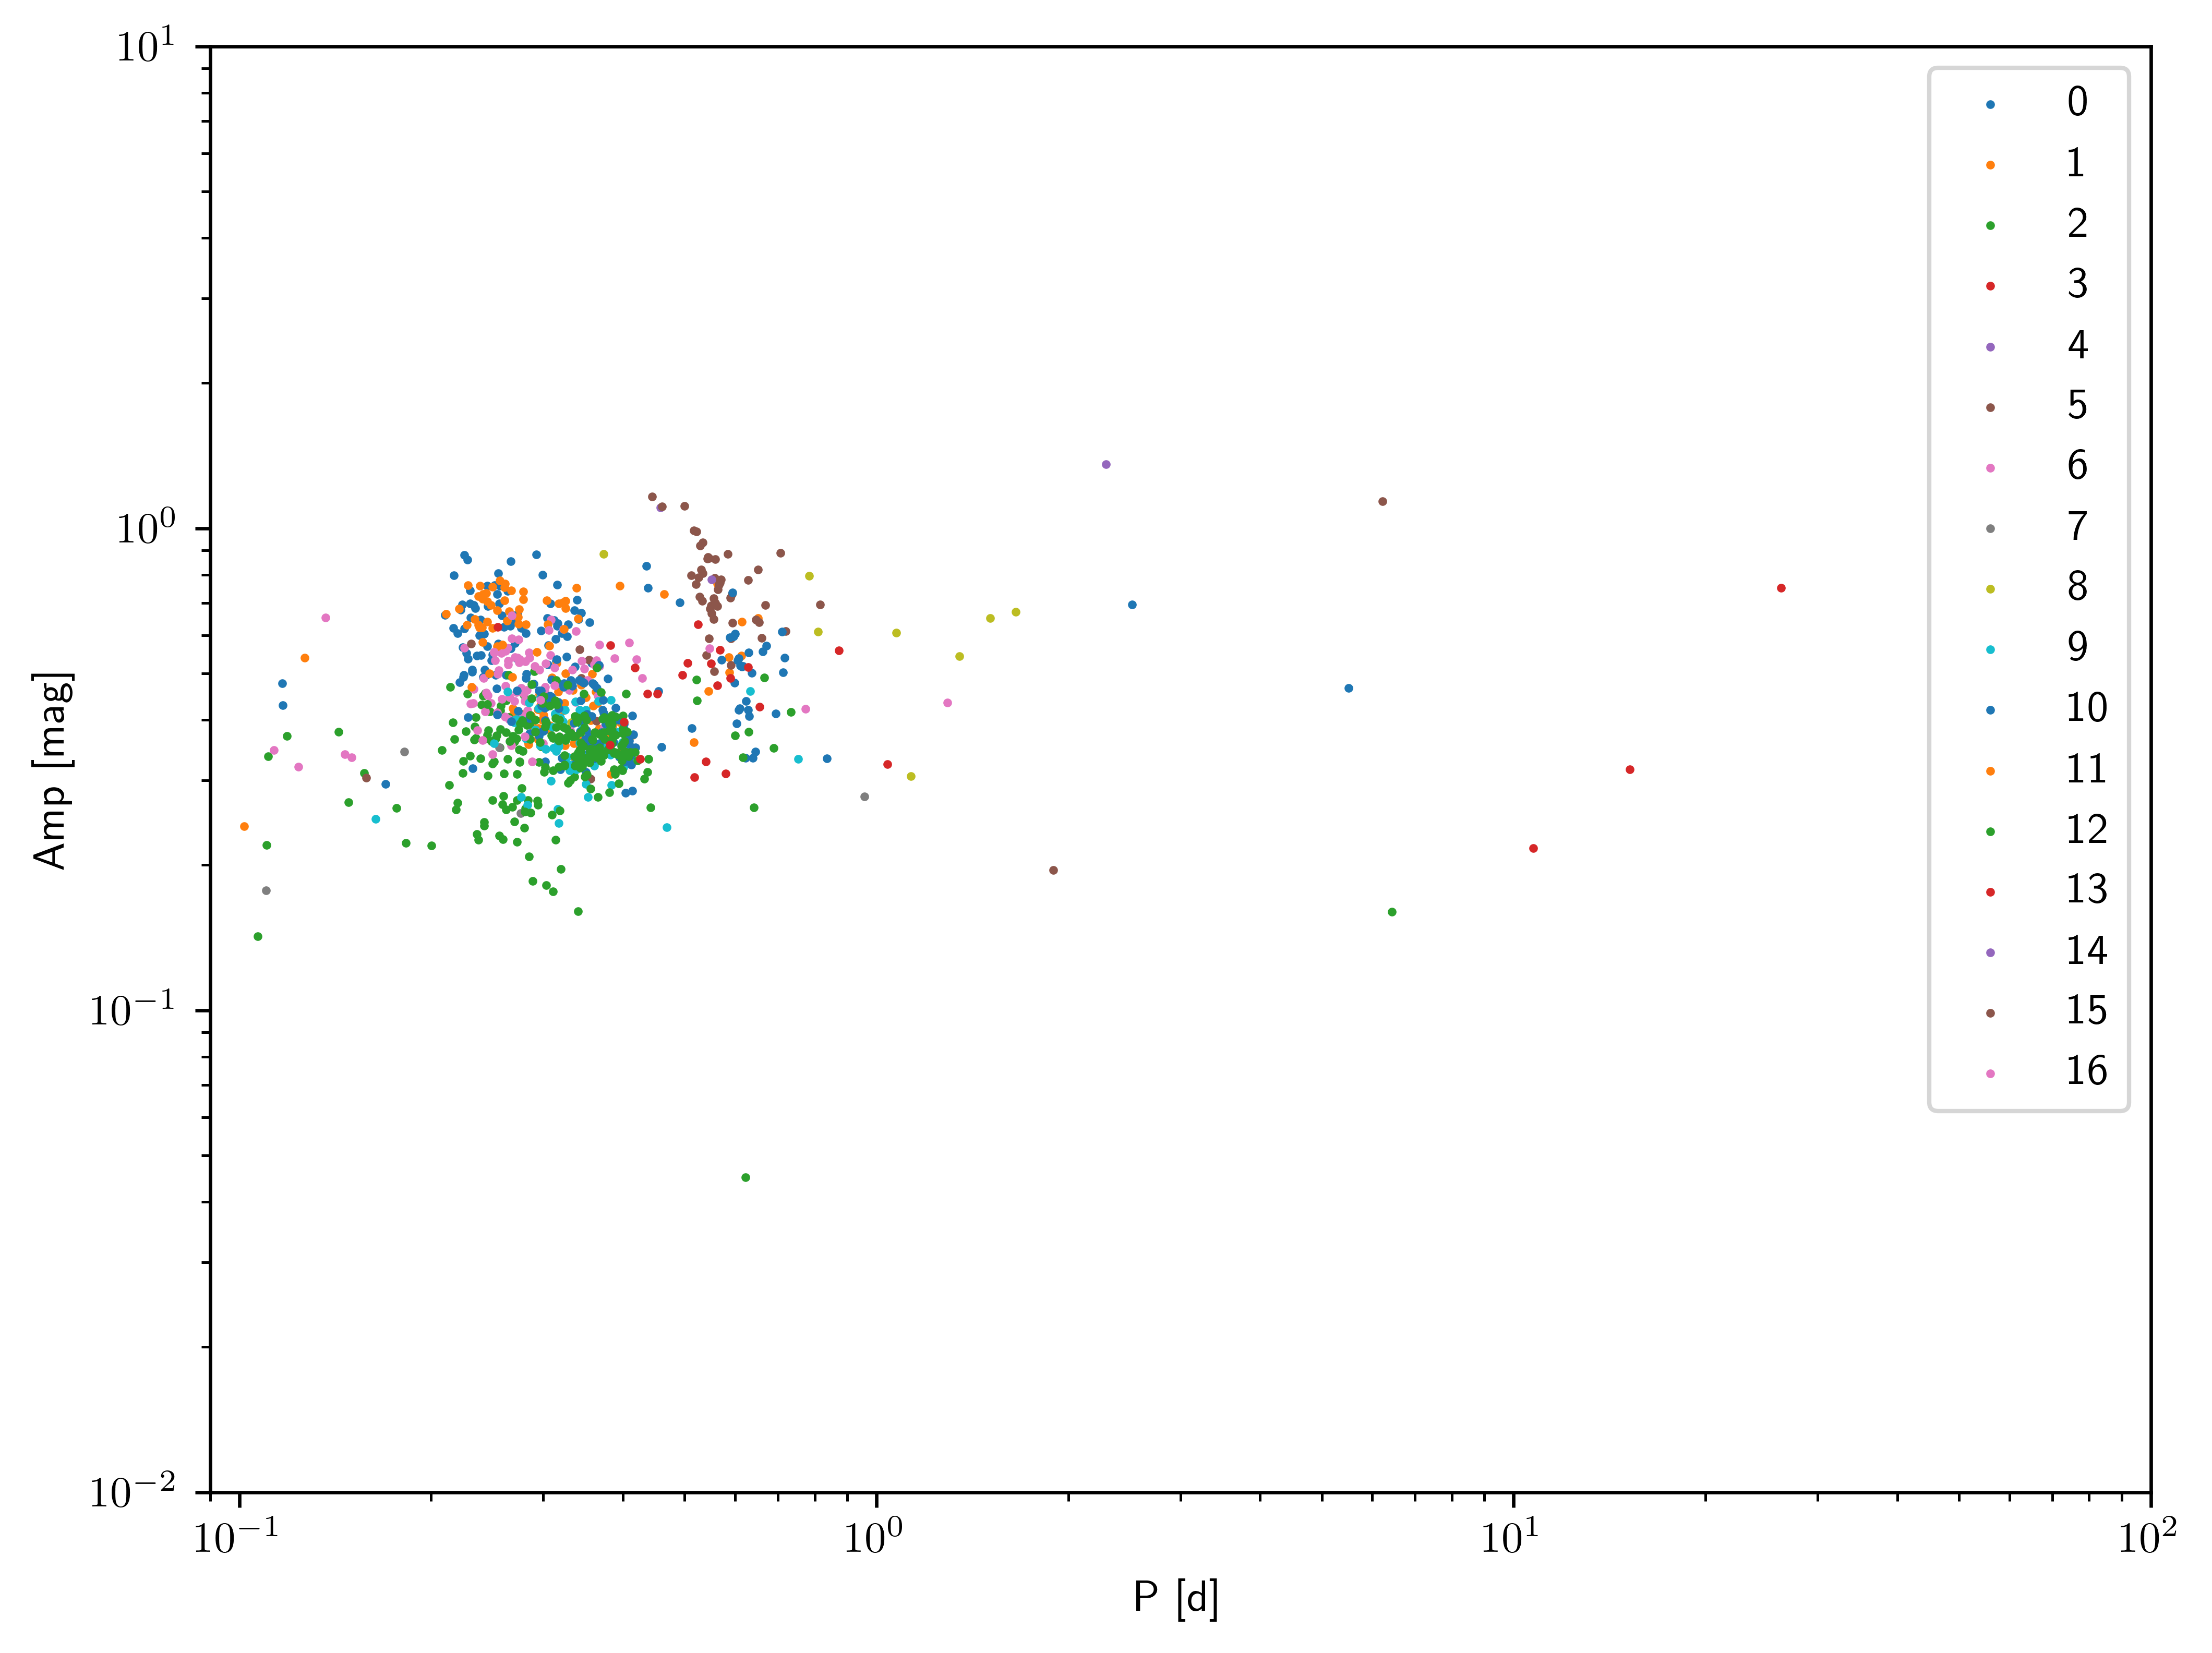

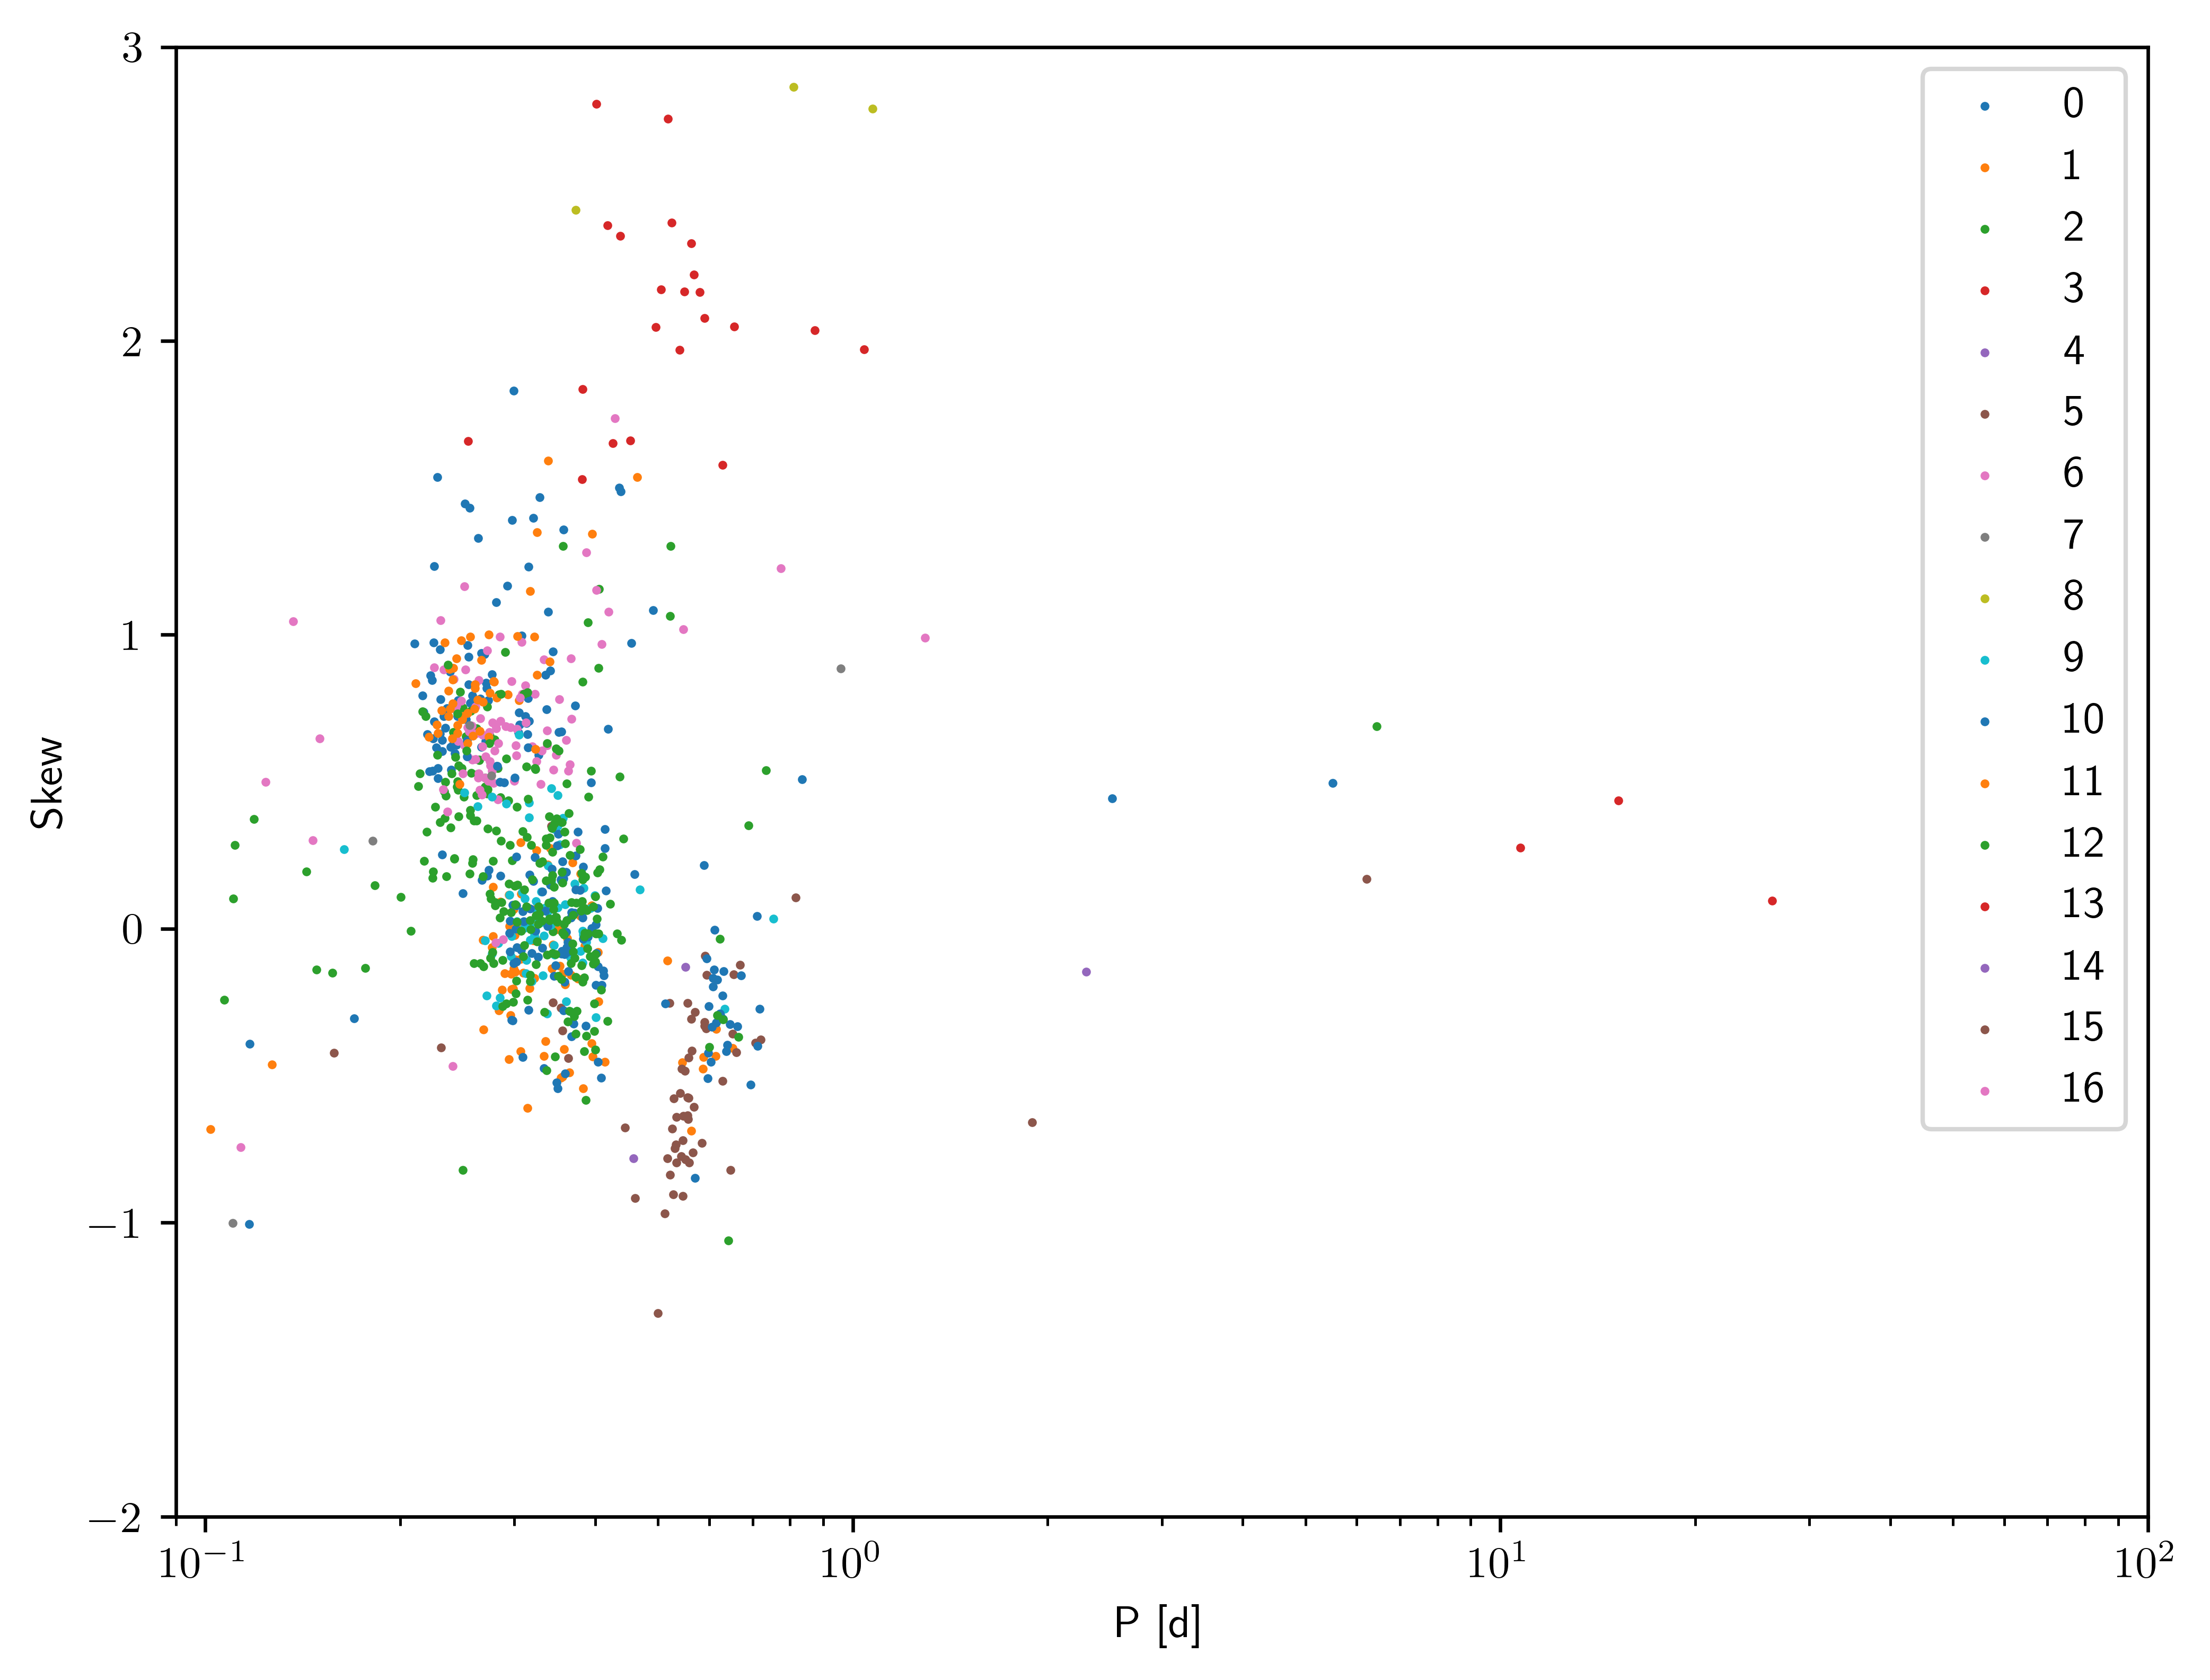

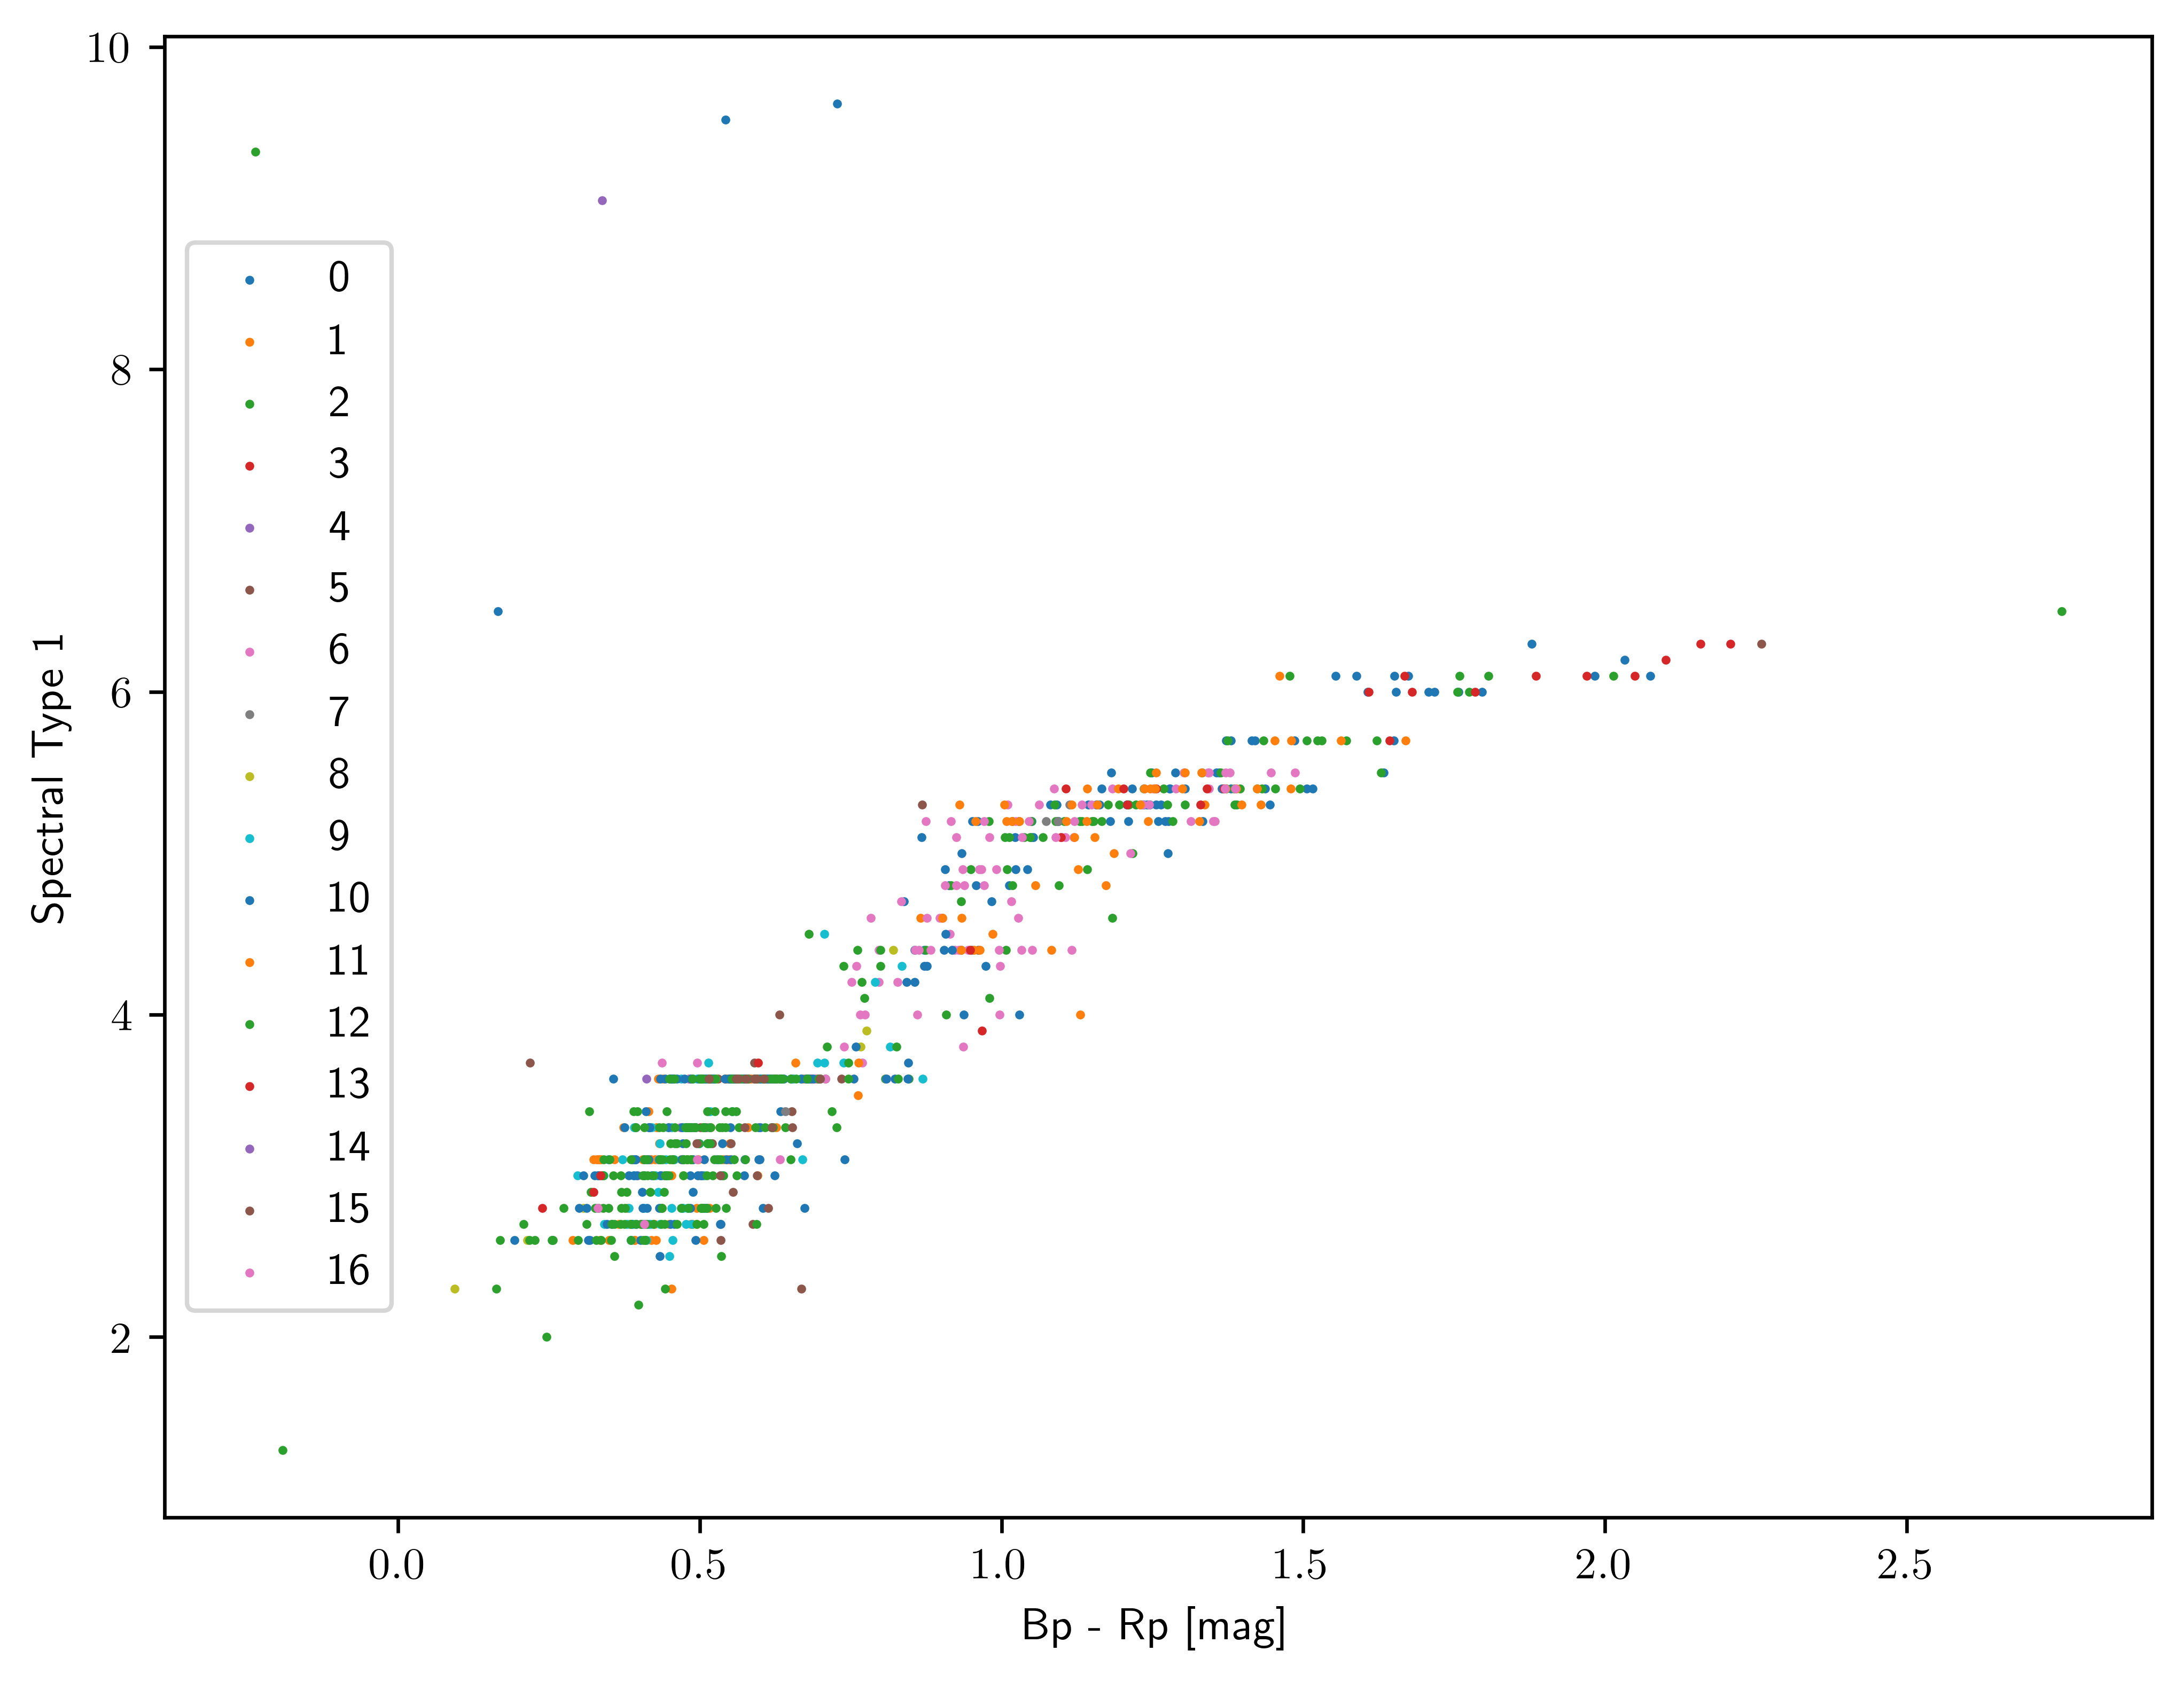

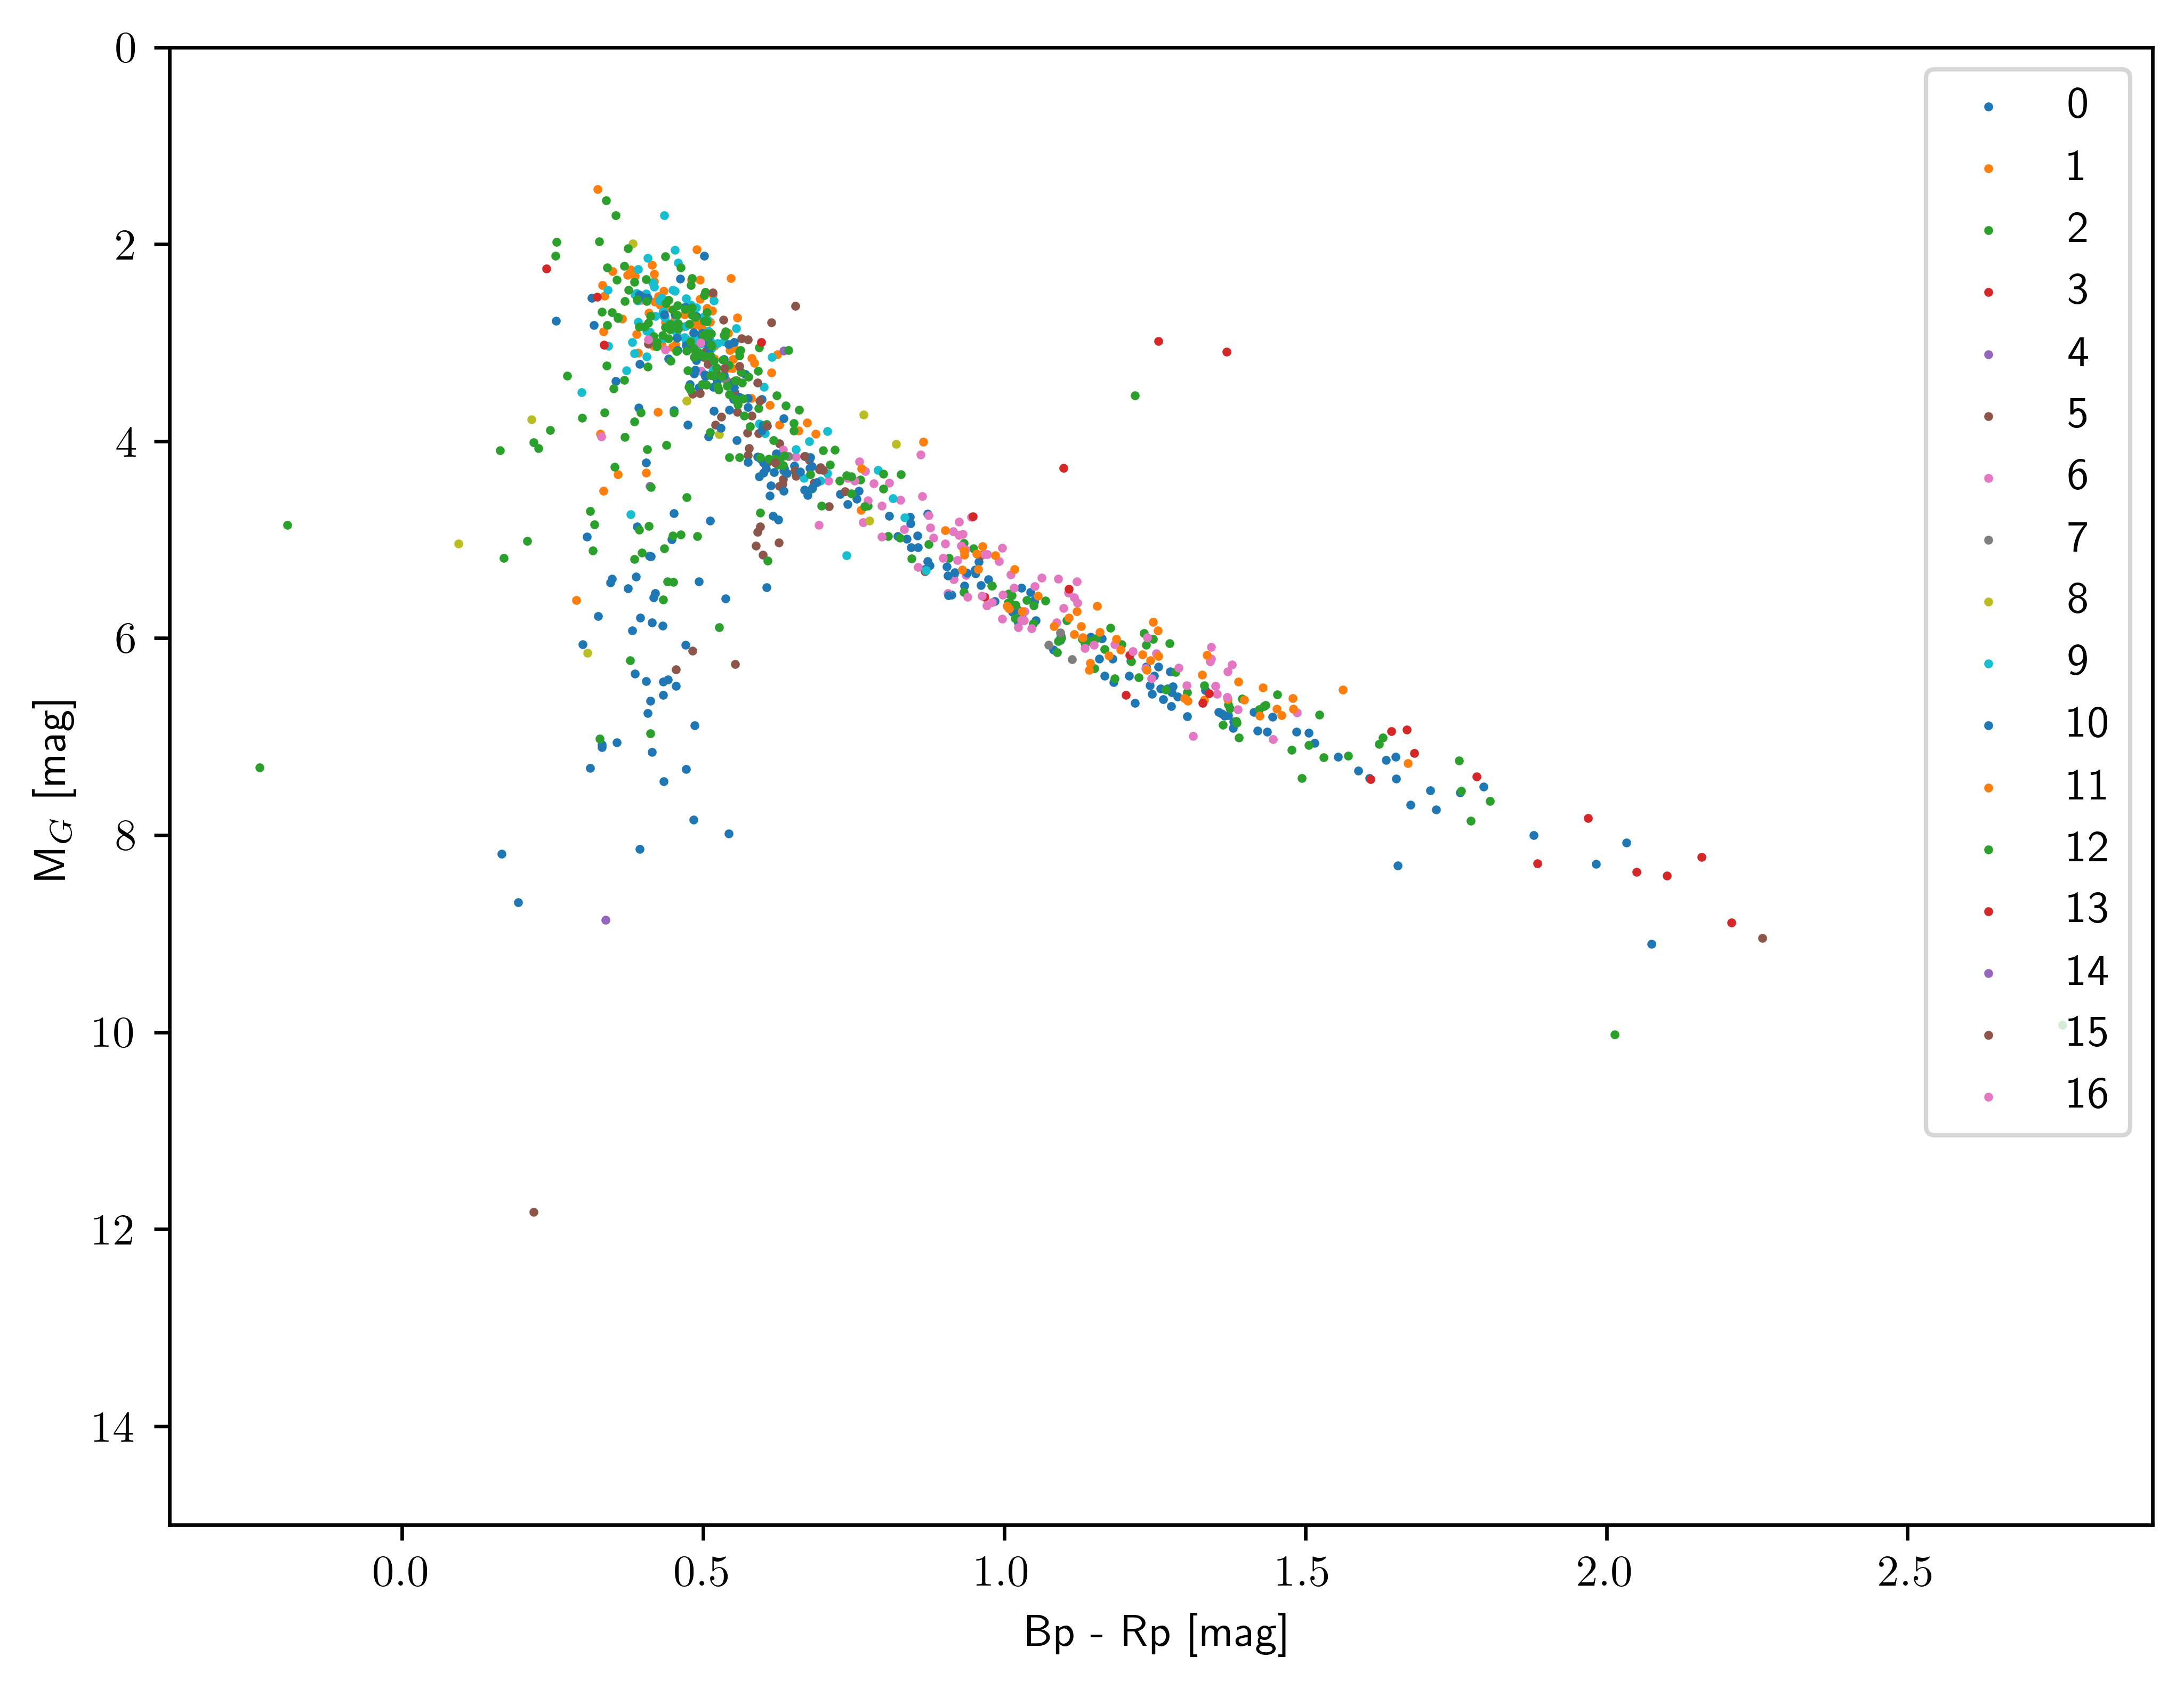

In [32]:
# %matplotlib widget
# %matplotlib inline  
# %matplotlib notebook

# selection_colnames.index('ZTF_r_lc_skew')

######################################################################

fig = plt.figure(figsize=(8,6), dpi=600)
for ii in np.unique(clustering.labels_):
    plt.scatter(X[:, selection_colnames.index('ZTF_r_P')][(clustering.labels_ == ii)], X[:, selection_colnames.index('ZTF_r_Amp')][(clustering.labels_ == ii)], s=1, label=ii)

plt.xlim(0.09,100)
plt.ylim(0.01,10)

plt.xscale('log')
plt.yscale('log')

plt.legend(loc='best')

plt.xlabel('P [d]')
plt.ylabel('Amp [mag]')

######################################################################

fig = plt.figure(figsize=(8,6), dpi=600)
for ii in np.unique(clustering.labels_):
    plt.scatter(X[:,selection_colnames.index('ZTF_r_P')][(clustering.labels_ == ii)], X[:,selection_colnames.index('ZTF_r_lc_skew')][(clustering.labels_ == ii)], s=1, label=ii)

plt.xlim(0.09,100)
plt.ylim(-2,3)

plt.xscale('log')
# plt.yscale('log')

plt.legend(loc='best')

plt.xlabel('P [d]')
plt.ylabel('Skew')


######################################################################


fig = plt.figure(figsize=(8,6), dpi=600)
for ii in np.unique(clustering.labels_):
    plt.scatter(X[:,selection_colnames.index('bp_rp')][(clustering.labels_ == ii)], X[:, selection_colnames.index('PyHammerSpecType1')][(clustering.labels_ == ii)], s=1, label=ii)

# plt.xlim(0.09,100)

# plt.xscale('log')
# plt.yscale('log')

plt.legend(loc='best')

plt.xlabel('Bp - Rp [mag]')
plt.ylabel('Spectral Type 1')

######################################################################


fig = plt.figure(figsize=(8,6), dpi=600)

for ii in np.unique(clustering.labels_):
    plt.scatter(X[:,selection_colnames.index('bp_rp')][(clustering.labels_ == ii)], X[:, selection_colnames.index('M_G')][(clustering.labels_ == ii)], s=1, label=ii)

plt.ylim(0.0,15)

# plt.xscale('log')
# plt.yscale('log')

plt.legend(loc='best')

plt.xlabel('Bp - Rp [mag]')
plt.ylabel('M$_G$ [mag]')

ax = plt.gca()
ax.invert_yaxis()

In [217]:

# from sklearn.cluster import AgglomerativeClustering
# clustering = AgglomerativeClustering(n_clusters=10).fit(X)
# print("######################################################################")
# print("AgglomerativeClustering")
# print(np.unique(clustering.labels_, return_counts=True))

######################################################################

from sklearn.cluster import KMeans
clustering = KMeans(n_clusters=17, n_init=100, max_iter=1000, algorithm='full').fit(X_scaled)
print("######################################################################")
print("KMeans")
print(np.unique(clustering.labels_, return_counts=True))

######################################################################

# from sklearn.cluster import MeanShift
# clustering = MeanShift(bandwidth=10, cluster_all=False, n_jobs=4).fit(X_scaled)
# print("######################################################################")
# print("MeanShift")
# print(np.unique(clustering.labels_, return_counts=True))

######################################################################

# import hdbscan
# clusterer = hdbscan.HDBSCAN(min_cluster_size=5,
#                             min_samples=None,
#                             metric='euclidean',
#                             alpha=1.0,
#                             cluster_selection_epsilon=0.0,
#                             algorithm='best',
#                             leaf_size=40,
#                             approx_min_span_tree=True,
#                             gen_min_span_tree=False,
#                             core_dist_n_jobs=4,
#                             cluster_selection_method='eom',
#                             allow_single_cluster=False,
#                             prediction_data=False,
#                             match_reference_implementation=False)
# clusterer.fit(X)
# # clusterer.fit(X_scaled)
# clustering = clusterer
# print("######################################################################")
# print("hdbscan")
# print(np.unique(clustering.labels_, return_counts=True))

######################################################################
KMeans
(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16],
      dtype=int32), array([ 16,  26,  28, 106,  27,  82,   5,  16, 160,   4, 117,  75,   9,
        80,  94,   1,   2]))


In [133]:
TDSS_Table = Table.read('/Users/benjaminroulston/Dropbox/Research/TDSS/Variable_Stars/WORKING_DIRECTORY/Statistical_Testing/LC_stat_calculations/Control_StatsCalc/TDSS_VarStar_FINAL_Var_ALL_PROP_STATS_03-15-2022.fits')
TDSS_Table.add_column(np.arange(len(TDSS_Table)), index=0, name='prop_id')

def print_DrakeClass_of_clusters(all_cluster_labels, TDSS_Table):
    Drake_num_to_vartype = Table.read("sup_data/"+"darke_var_types.txt", format='ascii.commented_header')
    Drake_class_per_cluster_table = Drake_num_to_vartype.copy()
    
    
    cluster_names = np.unique(all_cluster_labels)
    for ii in range(cluster_names.size):
        this_cluster = cluster_names[ii]
        cluster_indexs = np.where(all_cluster_labels==this_cluster)[0]
        
        this_cluster_ndrake  = TDSS_Table['isDrake', 'Drake_Per', 'Drake_Vamp', 'Drake_Cl', 'Drake_f_Cl', 'Drake_Simbad']['isDrake'][cluster_indexs].sum()
        unique_drake_class, num_in_class = np.unique(TDSS_Table['isDrake', 'Drake_Per', 'Drake_Vamp', 'Drake_Cl', 'Drake_f_Cl', 'Drake_Simbad']['Drake_Cl'][cluster_indexs], return_counts=True)
        
        holding_column = np.zeros(len(Drake_num_to_vartype))
        for ii, classType in enumerate(unique_drake_class[:-1]):
            holding_column[classType - 1] = num_in_class[:-1][ii]
        
        Drake_class_per_cluster_table.add_column(holding_column, name=f"Cluster_{this_cluster}")
        
    return Drake_class_per_cluster_table

cluster_counts = print_DrakeClass_of_clusters(clustering.labels_, TDSS_Table[selection_index])
cluster_counts.show_in_notebook(display_length=len(cluster_counts))

idx,num_Class,Var_Type,Cluster_0,Cluster_1,Cluster_2,Cluster_3,Cluster_4,Cluster_5,Cluster_6,Cluster_7,Cluster_8,Cluster_9,Cluster_10,Cluster_11,Cluster_12,Cluster_13,Cluster_14,Cluster_15,Cluster_16
0,1,EW,77.0,38.0,0.0,0.0,0.0,4.0,0.0,25.0,0.0,0.0,26.0,197.0,1.0,0.0,0.0,0.0,0.0
1,2,EA,0.0,0.0,0.0,0.0,0.0,20.0,0.0,0.0,0.0,0.0,4.0,5.0,1.0,0.0,0.0,0.0,0.0
2,3,EB,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,3.0,0.0,0.0,0.0,0.0,0.0
3,4,RRab,14.0,27.0,0.0,2.0,32.0,0.0,0.0,0.0,0.0,6.0,0.0,0.0,0.0,0.0,0.0,0.0,20.0
4,5,RRc,223.0,62.0,0.0,0.0,2.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,19.0
5,6,RRd,6.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0
6,7,Blazhko,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0
7,8,RS*\*CVn,2.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
8,9,ACEP,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,10,Cep-II,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [222]:
TDSS_Table = Table.read('/Users/benjaminroulston/Dropbox/Research/TDSS/Variable_Stars/WORKING_DIRECTORY/Statistical_Testing/LC_stat_calculations/Control_StatsCalc/TDSS_VarStar_FINAL_Var_ALL_PROP_STATS_03-15-2022.fits')
TDSS_Table.add_column(np.arange(len(TDSS_Table)), index=0, name='prop_id')

def print_DrakeClass_of_clusters(all_cluster_labels, TDSS_Table):
    Drake_num_to_vartype = Table.read("sup_data/"+"darke_var_types.txt", format='ascii.commented_header')
    Drake_class_per_cluster_table = Drake_num_to_vartype.copy()
    
    
    cluster_names = np.unique(all_cluster_labels)
    for ii in range(cluster_names.size):
        this_cluster = cluster_names[ii]
        cluster_indexs = np.where(all_cluster_labels==this_cluster)[0]
        
        this_cluster_ndrake  = TDSS_Table['isDrake', 'Drake_Per', 'Drake_Vamp', 'Drake_Cl', 'Drake_f_Cl', 'Drake_Simbad']['isDrake'][cluster_indexs].sum()
        unique_drake_class, num_in_class = np.unique(TDSS_Table['isDrake', 'Drake_Per', 'Drake_Vamp', 'Drake_Cl', 'Drake_f_Cl', 'Drake_Simbad']['Drake_Cl'][cluster_indexs], return_counts=True)
        
        holding_column = np.zeros(len(Drake_num_to_vartype))
        for ii, classType in enumerate(unique_drake_class[:-1]):
            holding_column[classType - 1] = num_in_class[:-1][ii]
        
        Drake_class_per_cluster_table.add_column(holding_column, name=f"Cluster_{this_cluster}")
        
    return Drake_class_per_cluster_table

cluster_counts = print_DrakeClass_of_clusters(clustering.labels_, TDSS_Table[selection_index])
cluster_counts.show_in_notebook(display_length=len(cluster_counts))

idx,num_Class,Var_Type,Cluster_0,Cluster_1,Cluster_2,Cluster_3,Cluster_4,Cluster_5,Cluster_6,Cluster_7,Cluster_8,Cluster_9,Cluster_10,Cluster_11,Cluster_12,Cluster_13,Cluster_14,Cluster_15,Cluster_16
0,1,EW,6.0,6.0,26.0,10.0,0.0,73.0,3.0,0.0,32.0,0.0,10.0,69.0,5.0,78.0,50.0,0.0,0.0
1,2,EA,0.0,19.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,2.0,0.0,1.0,1.0,0.0,0.0
2,3,EB,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0
3,4,RRab,3.0,0.0,0.0,9.0,25.0,0.0,0.0,14.0,4.0,0.0,38.0,0.0,0.0,0.0,7.0,0.0,1.0
4,5,RRc,0.0,0.0,0.0,82.0,0.0,0.0,0.0,0.0,116.0,0.0,65.0,0.0,3.0,0.0,35.0,0.0,0.0
5,6,RRd,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,5.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
6,7,Blazhko,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,8,RS*\*CVn,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
8,9,ACEP,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,10,Cep-II,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


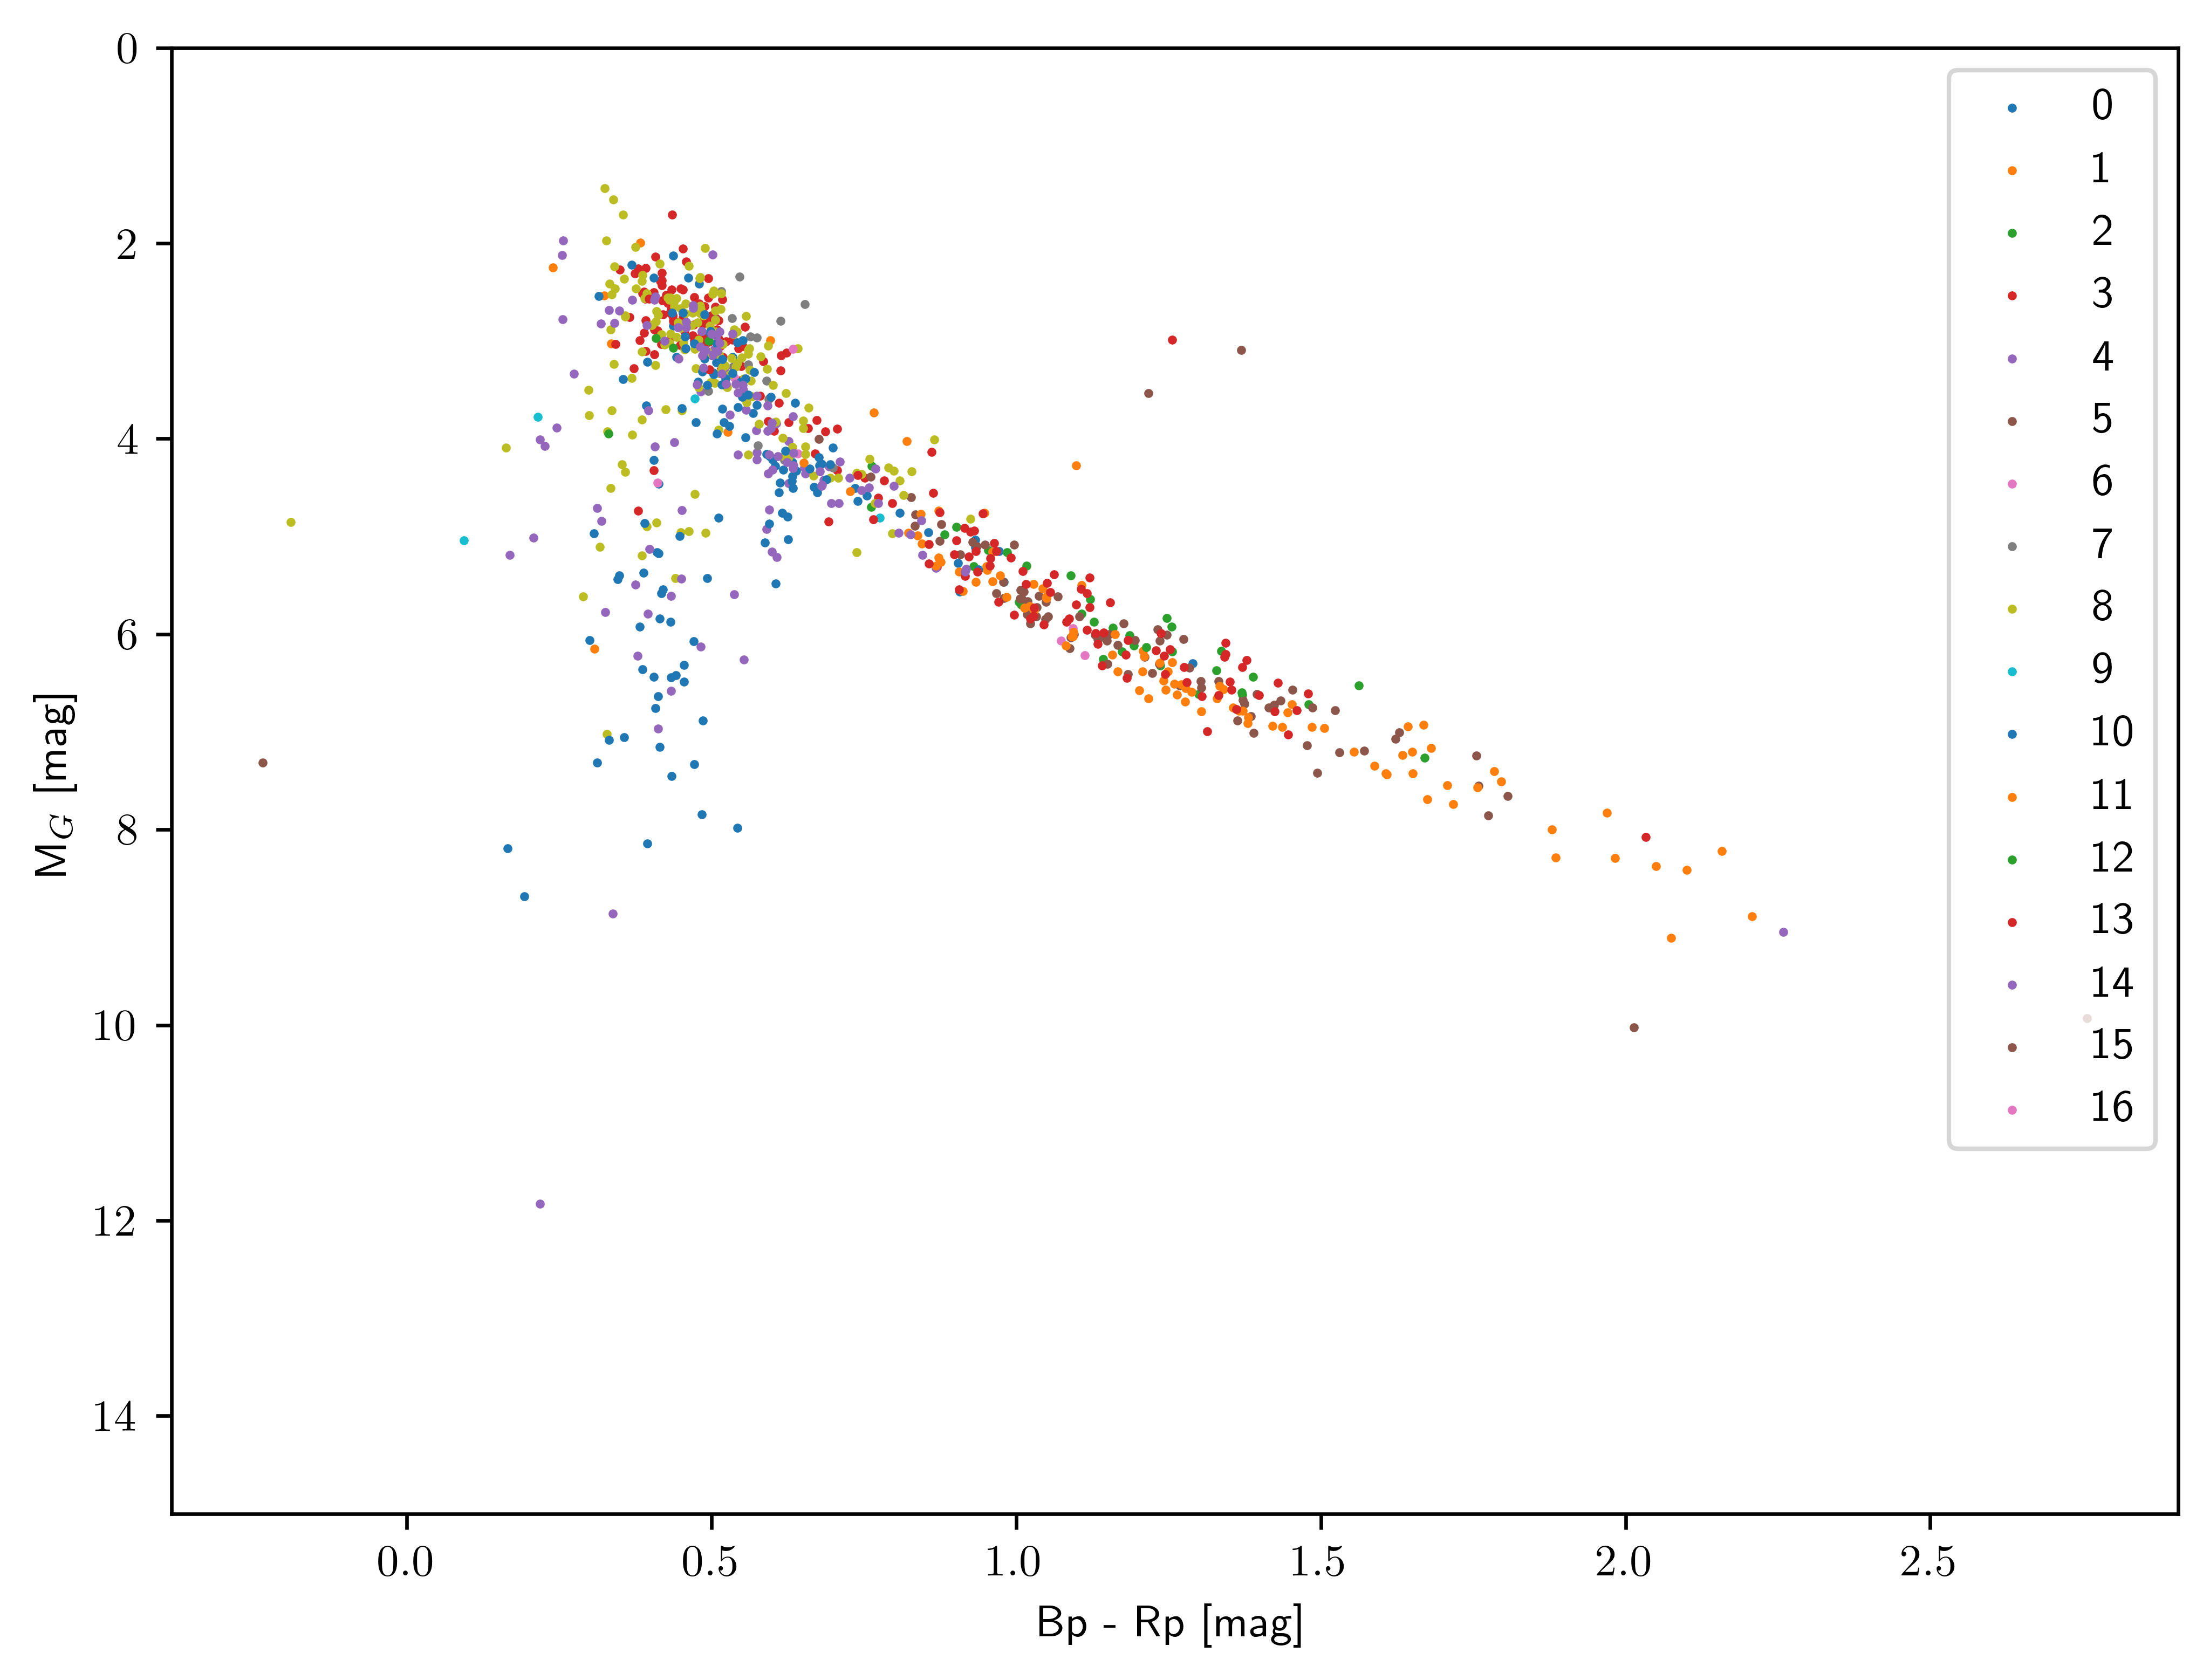

In [221]:
fig = plt.figure(figsize=(8,6), dpi=600)

for ii in np.unique(clustering.labels_):
    plt.scatter(X[:,selection_colnames.index('bp_rp')][(clustering.labels_ == ii)], X[:, selection_colnames.index('M_G')][(clustering.labels_ == ii)], s=1, label=ii)

plt.ylim(0.0,15)

# plt.xscale('log')
# plt.yscale('log')

plt.legend(loc='best')

plt.xlabel('Bp - Rp [mag]')
plt.ylabel('M$_G$ [mag]')

ax = plt.gca()
ax.invert_yaxis()

Text(0, 0.5, 'Spectral Type 1')

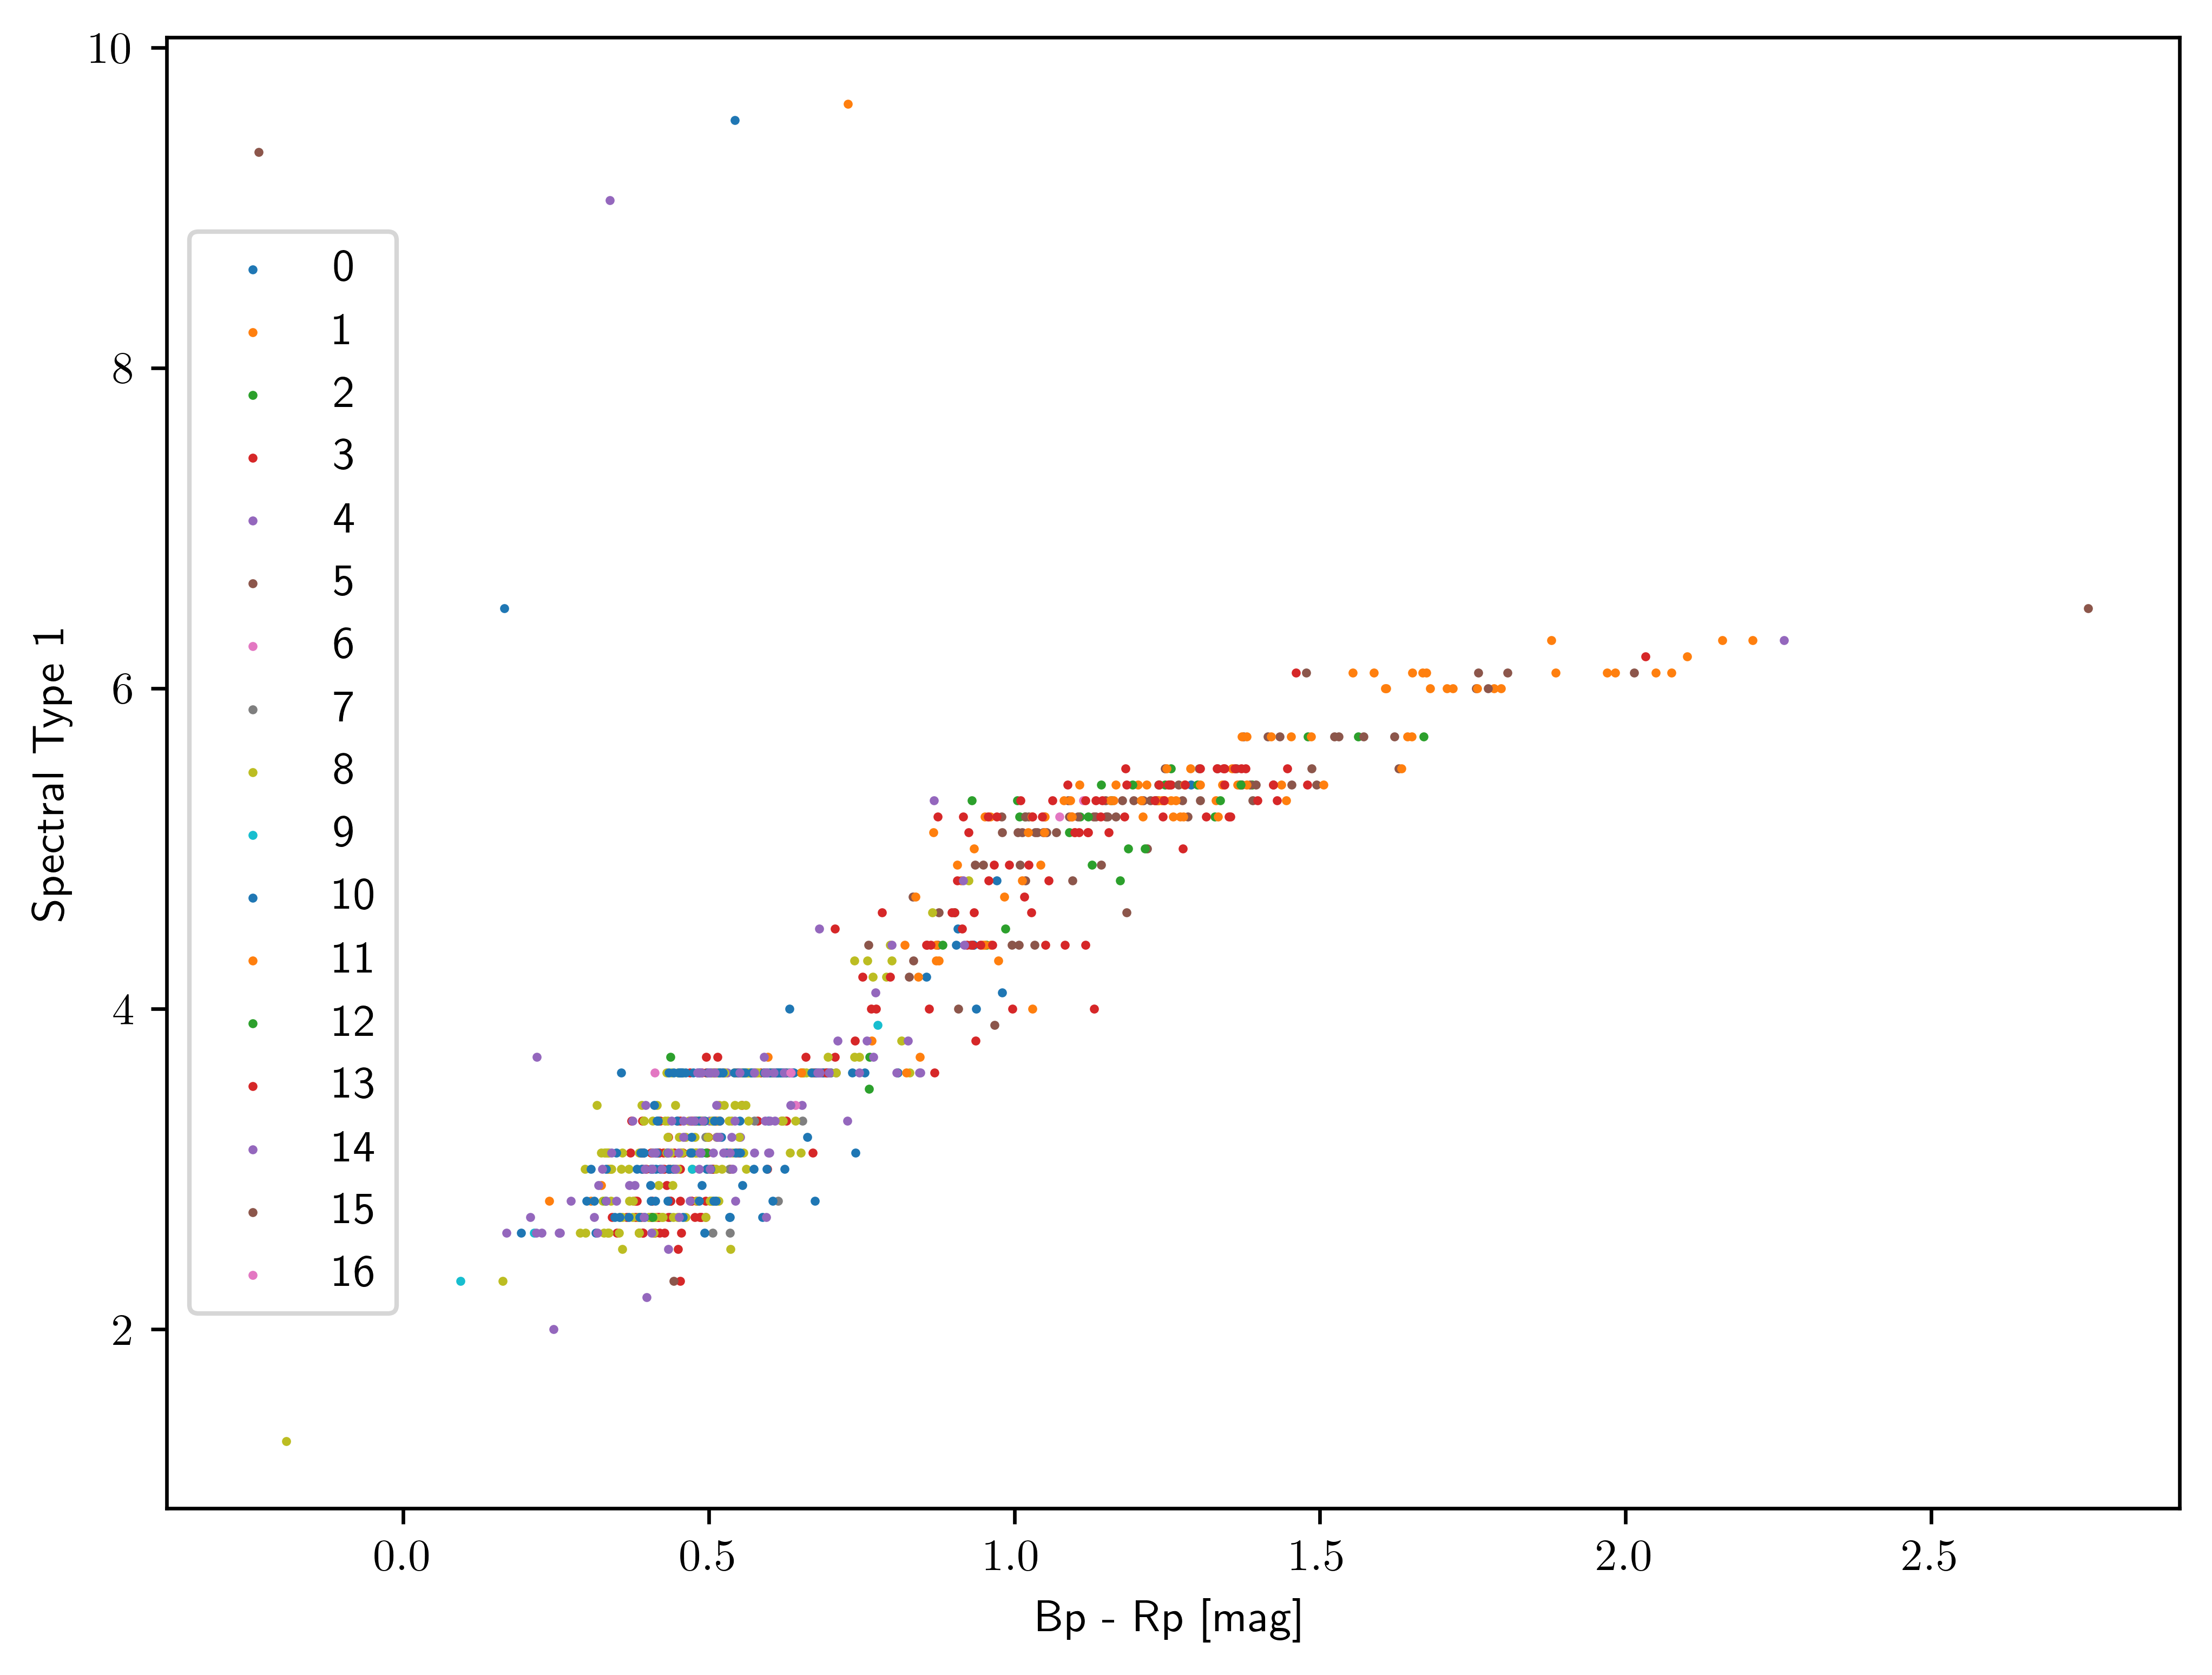

In [220]:
fig = plt.figure(figsize=(8,6), dpi=600)
for ii in np.unique(clustering.labels_):
    plt.scatter(X[:,selection_colnames.index('bp_rp')][(clustering.labels_ == ii)], X[:, selection_colnames.index('PyHammerSpecType1')][(clustering.labels_ == ii)], s=1, label=ii)

# plt.xlim(0.09,100)

# plt.xscale('log')
# plt.yscale('log')

plt.legend(loc='best')

plt.xlabel('Bp - Rp [mag]')
plt.ylabel('Spectral Type 1')


Text(0, 0.5, 'Skew')

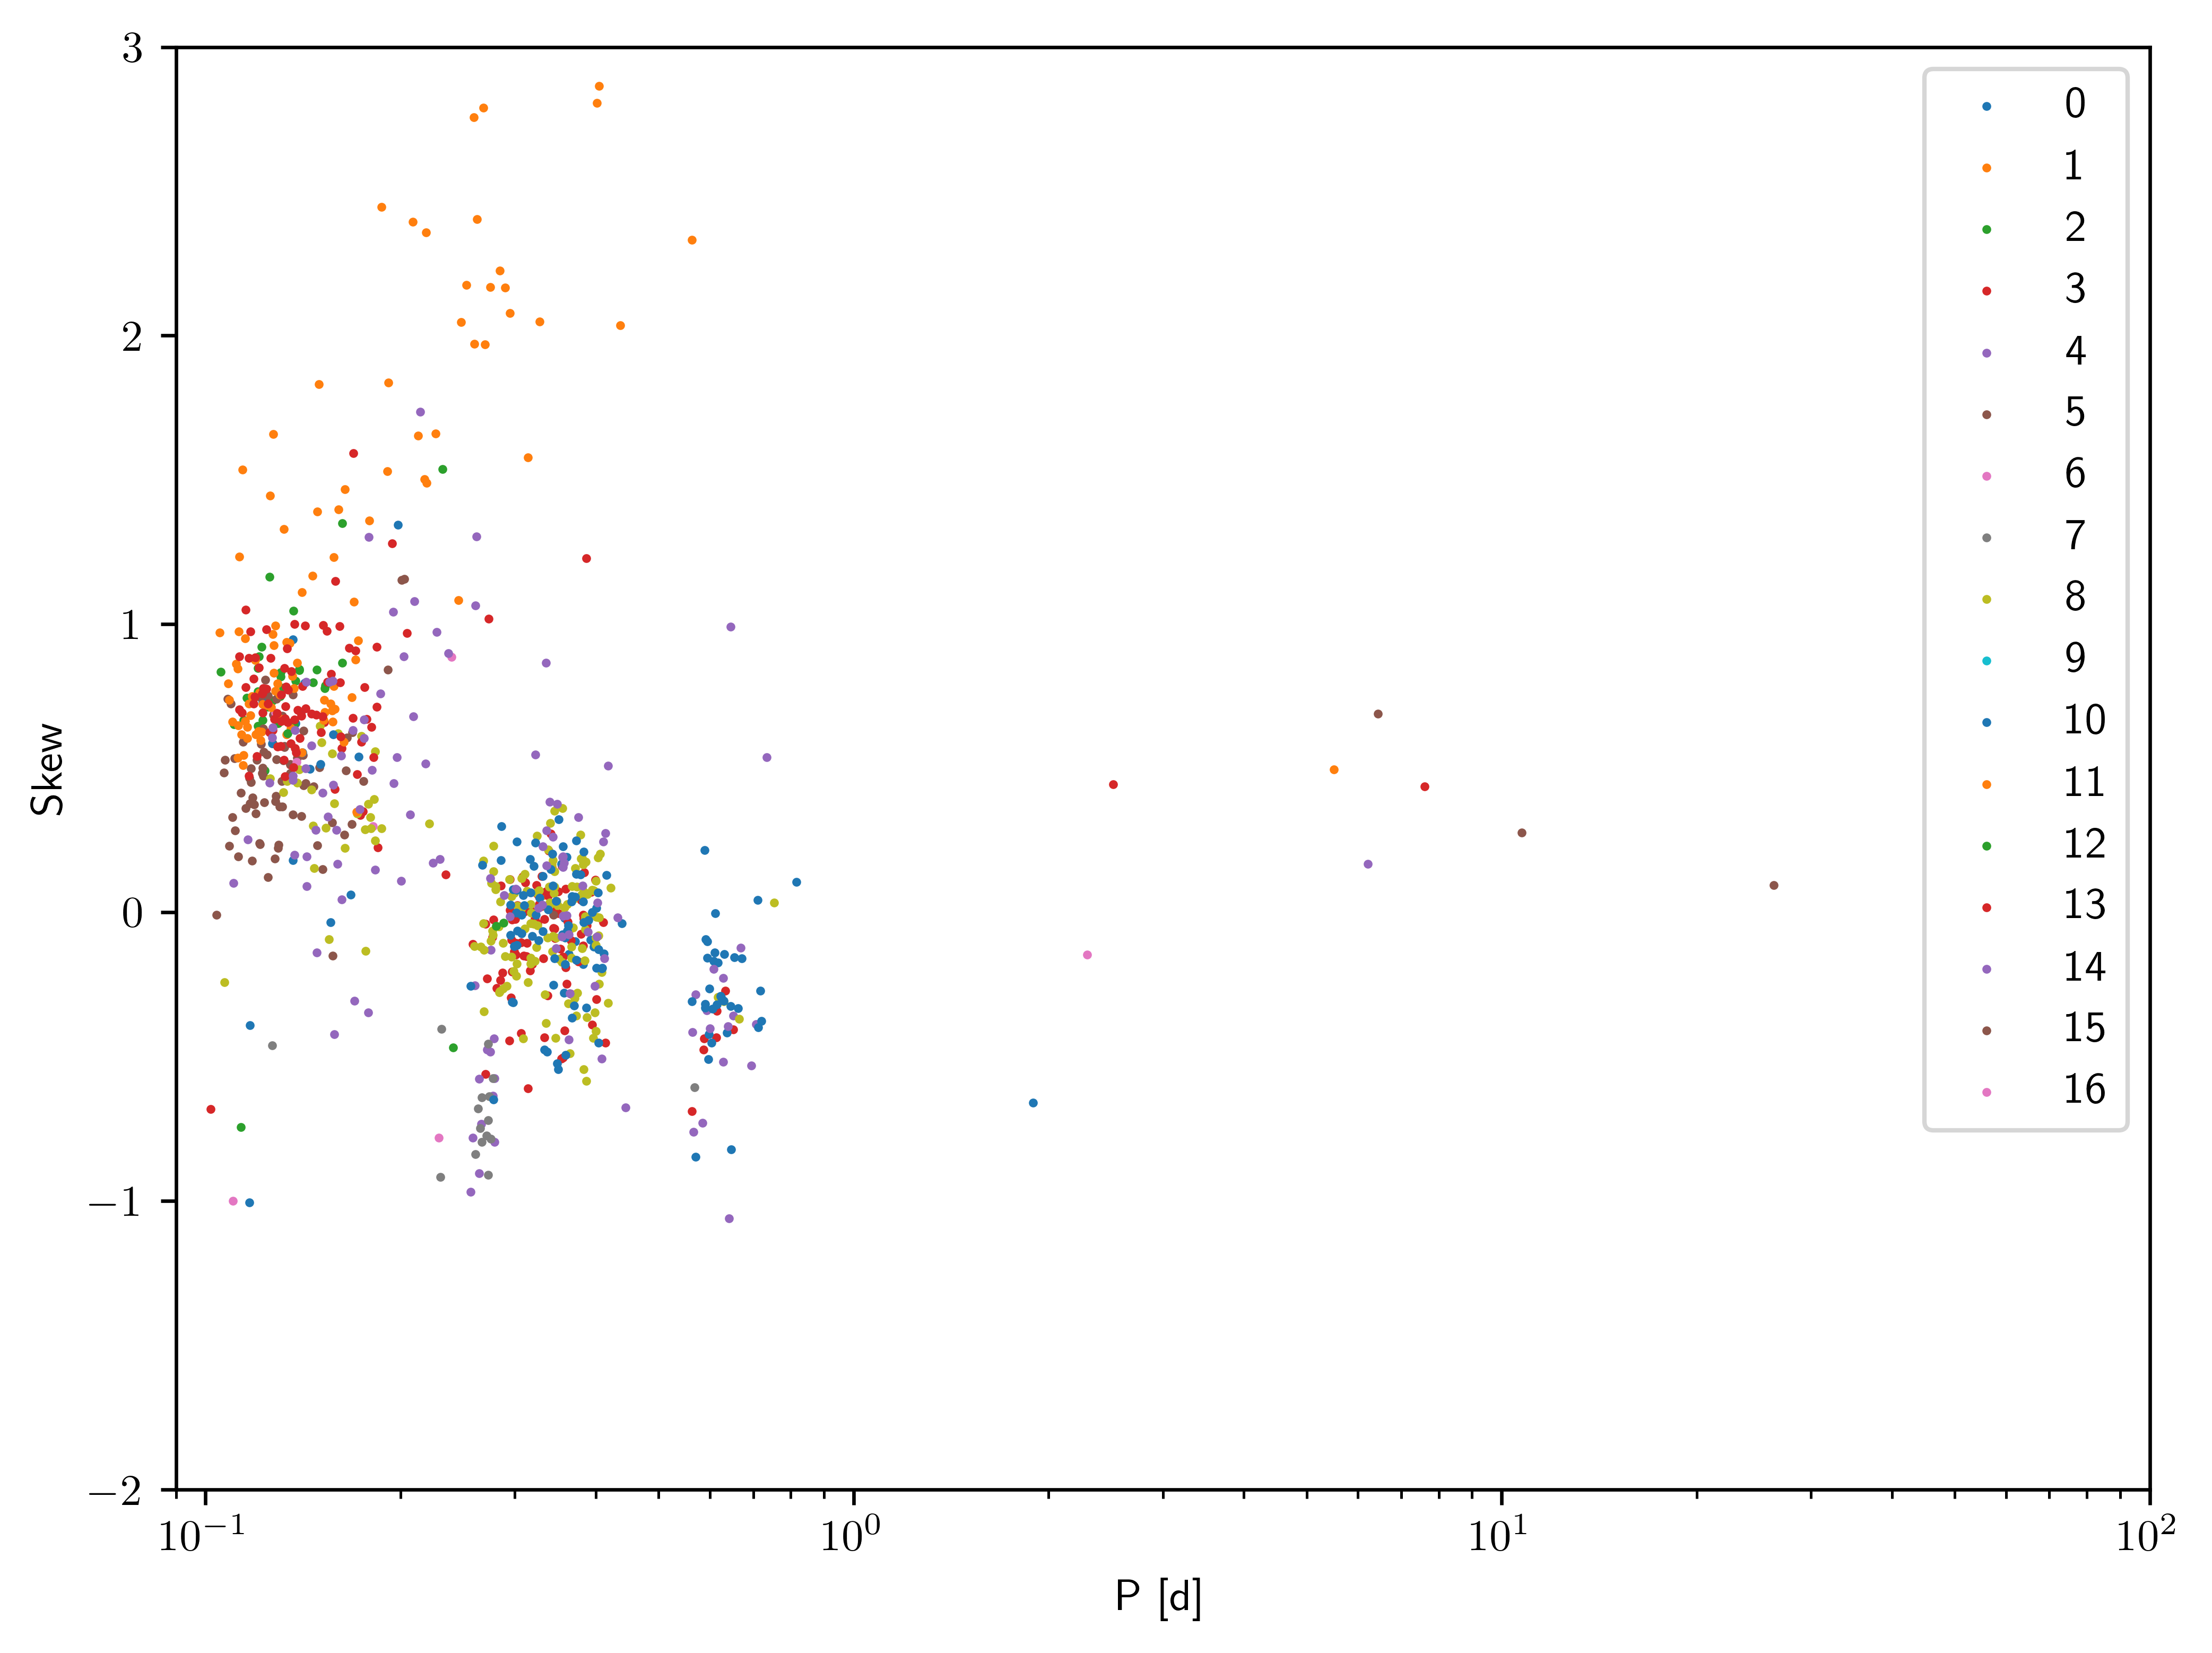

In [219]:
fig = plt.figure(figsize=(8,6), dpi=600)
for ii in np.unique(clustering.labels_):
    plt.scatter(X[:,selection_colnames.index('ZTF_r_P')][(clustering.labels_ == ii)], X[:,selection_colnames.index('ZTF_r_lc_skew')][(clustering.labels_ == ii)], s=1, label=ii)

plt.xlim(0.09,100)
plt.ylim(-2,3)

plt.xscale('log')
# plt.yscale('log')

plt.legend(loc='best')

plt.xlabel('P [d]')
plt.ylabel('Skew')


Text(0, 0.5, 'Amp [mag]')

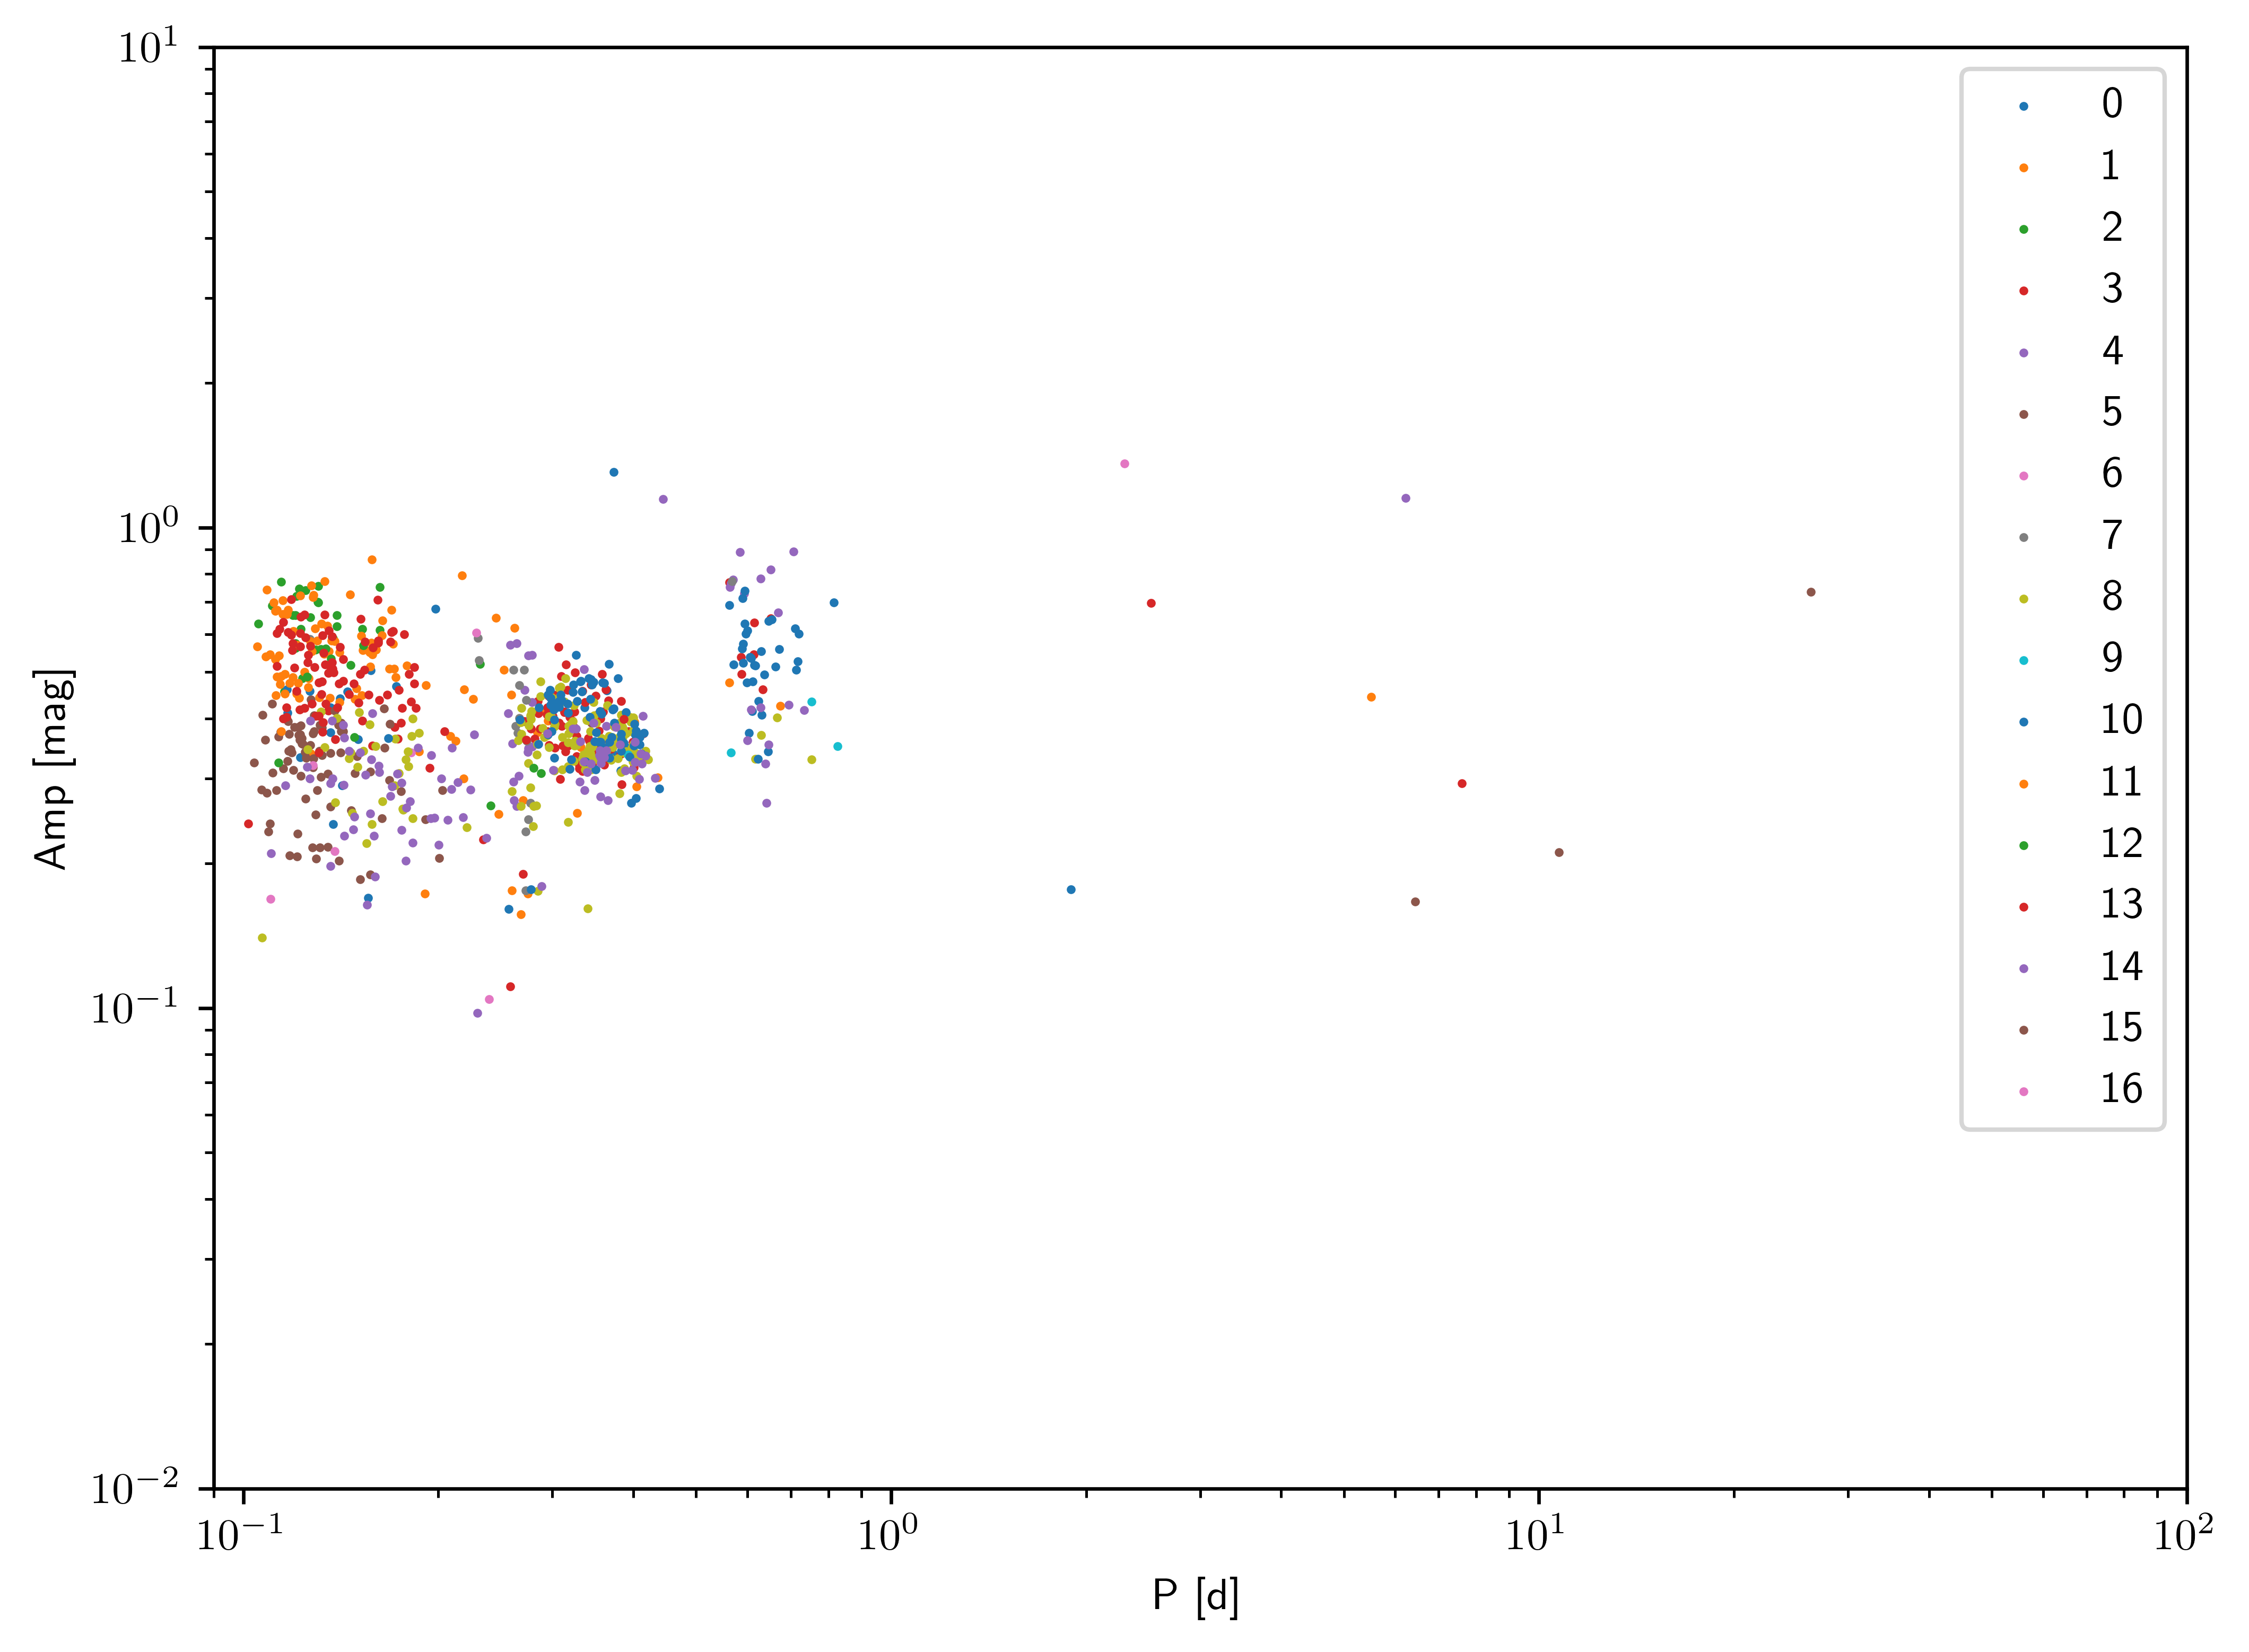

In [218]:
fig = plt.figure(figsize=(8,6), dpi=600)
for ii in np.unique(clustering.labels_):
    plt.scatter(X[:, selection_colnames.index('ZTF_r_P')][(clustering.labels_ == ii)], X[:, selection_colnames.index('ZTF_r_Amp')][(clustering.labels_ == ii)], s=1, label=ii)

plt.xlim(0.09,100)
plt.ylim(0.01,10)

plt.xscale('log')
plt.yscale('log')

plt.legend(loc='best')

plt.xlabel('P [d]')
plt.ylabel('Amp [mag]')

In [135]:
def make_ML_dirs(cluster_names, test_dir_name='temp_test', ml_dir="/Users/benjaminroulston/Dropbox/Research/TDSS/Variable_Stars/WORKING_DIRECTORY/Classification/Unsupervised/"):
    datestr = check_output(["/bin/date","+%F"])
    datestr = datestr.decode().replace('\n', '')
    if not os.path.exists(ml_dir+datestr):
        os.mkdir(ml_dir+datestr)

    test_dir = ml_dir + datestr + f"/{test_dir_name}/"
    if not os.path.exists(test_dir):
        os.mkdir(test_dir)
    
    cluster_dirs = []
    for this_clust_name in cluster_names:
        hold_dir = test_dir + f"{this_clust_name}/"
        cluster_dirs.append(hold_dir)
        if not os.path.exists(hold_dir):
            os.mkdir(hold_dir)
        
    return cluster_dirs, test_dir, datestr


def send_Vi_panel_clusters(all_cluster_labels, TDSS_Table, Vi_datestr, test_dir_name='temp_test', ml_dir="/Users/benjaminroulston/Dropbox/Research/TDSS/Variable_Stars/WORKING_DIRECTORY/Classification/Unsupervised/"):
    cluster_names = np.unique(all_cluster_labels)
    cluster_dirs, test_dir, ML_datestr = make_ML_dirs(cluster_names, test_dir_name=test_dir_name, ml_dir=ml_dir)
    
    for ii in range(cluster_names.size):
        this_cluster = cluster_names[ii]
        if this_cluster!=3:
            cluster_indexs = np.where(all_cluster_labels==this_cluster)[0]
            vi.get_Vi_panels(cluster_indexs, TDSS_Table, Vi_datestr, copy=True, moveDir=cluster_dirs[ii])
        print(f"Cluster {this_cluster} has been moved.")
    

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=UserWarning)
    send_Vi_panel_clusters(clustering.labels_, TDSS_Table[selection_index], '2022-04-05', test_dir_name='temp_test', ml_dir="/Users/benjaminroulston/Dropbox/Research/TDSS/Variable_Stars/WORKING_DIRECTORY/Classification/Unsupervised/")

516it [00:06, 76.59it/s]


Cluster 0 has been moved.


413it [00:06, 68.29it/s]


Cluster 1 has been moved.


1it [00:00, 52.76it/s]


Cluster 2 has been moved.
Cluster 3 has been moved.


321it [00:04, 66.12it/s]


Cluster 4 has been moved.


94it [00:01, 64.75it/s]


Cluster 5 has been moved.


2it [00:00, 51.89it/s]


Cluster 6 has been moved.


294it [00:04, 60.24it/s]


Cluster 7 has been moved.


12it [00:00, 60.97it/s]


Cluster 8 has been moved.


202it [00:03, 62.21it/s]


Cluster 9 has been moved.


165it [00:03, 52.89it/s]


Cluster 10 has been moved.


279it [00:05, 49.86it/s]


Cluster 11 has been moved.


182it [00:03, 49.72it/s]


Cluster 12 has been moved.


1it [00:00, 50.54it/s]


Cluster 13 has been moved.


12it [00:00, 51.46it/s]


Cluster 14 has been moved.


2it [00:00, 42.37it/s]


Cluster 15 has been moved.


424it [00:08, 47.85it/s]

Cluster 16 has been moved.


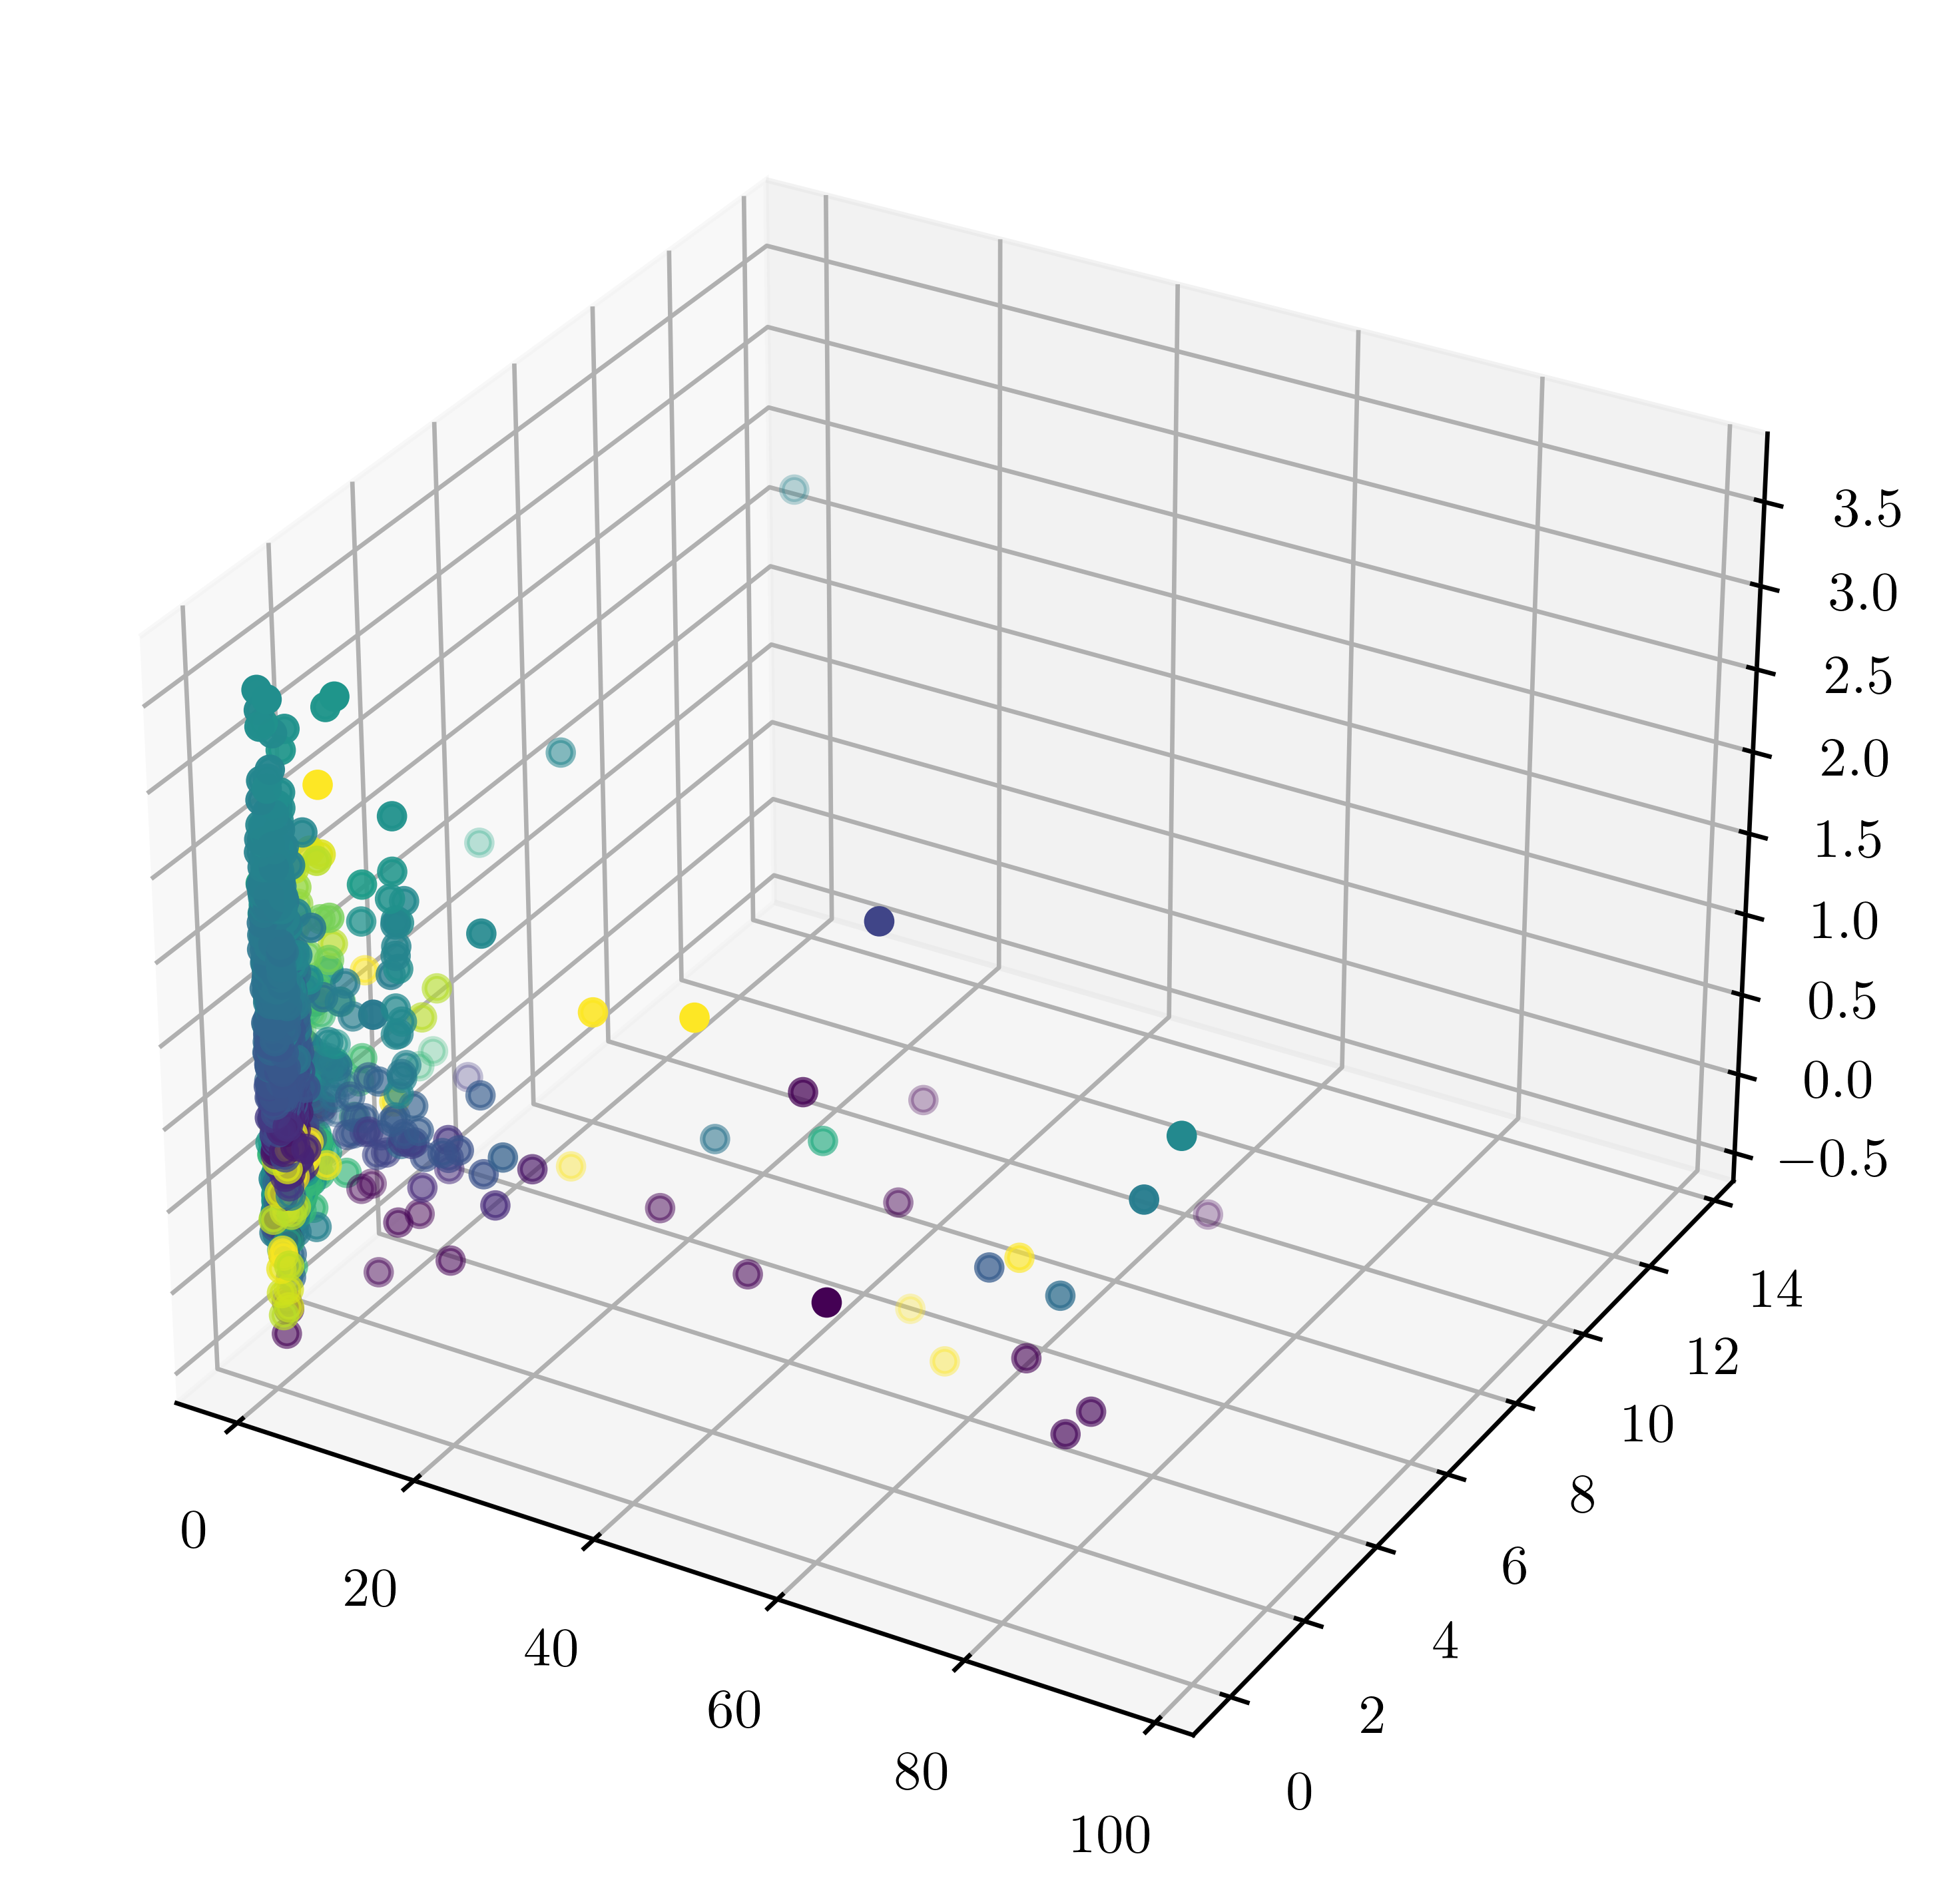

In [178]:
fig = plt.figure(figsize=(8,6), dpi=600)
ax = fig.add_subplot(projection='3d')

for ii in np.unique(clustering.labels_):
    ax.scatter(X[:,1][(clustering.labels_ == ii)],
                X[:, 5][(clustering.labels_ == ii)],
                X[:, 0][(clustering.labels_ == ii)],
                c=X[:, 6][(clustering.labels_ == ii)], label=ii)

# ax.xlim(0.01,100)



In [33]:
# <function corner.corner.corner(data, bins=20, *, range=None,
# weights=None, color='k', hist_bin_factor=1, smooth=None, smooth1d=None,
# labels=None, label_kwargs=None, titles=None, show_titles=False, title_fmt='.2f',
# title_kwargs=None, truths=None, truth_color='#4682b4', scale_hist=False, quantiles=None,
# verbose=False, fig=None, max_n_ticks=5, top_ticks=False, use_math_text=False,
# reverse=False, labelpad=0.0, hist_kwargs=None, group='posterior', var_names=None, 
# filter_vars=None, coords=None, divergences=False, divergences_kwargs=None, labeller=None,
# **hist2d_kwargs)>
K = pca_X.shape[1]
fig, axes = plt.subplots(K, K, figsize=(12, 12), dpi=600)

corner_plot = corner.corner(pca_X, bins=25, range=None, fig=fig,
                    labels=selected_data.colnames,
                    quantiles=[0.16, 0.5, 0.84],
                    show_titles=True, title_kwargs={"fontsize": 12})


# corner_range = [(-0.1, 4.5), (0, 18), (0, 25), (0, 2), (-4, 4), (0, 1), (0, 3), (1, 10), (1, 10)]
# # corner_range = [(-0.1,4.5), (0,18), (0,10), (0,10), (0,10), (0,10), (0,10), (0,10), (0,10)]


# corner_plot = corner.corner(X, bins=25, range=None, fig=fig,
#                     labels=selected_data.colnames,
#                     quantiles=[0.16, 0.5, 0.84],
#                     show_titles=True, title_kwargs={"fontsize": 12})

# plt.savefig("test2.pdf", dpi=600)

# for ii in np.arange(0, 81, 9):
#     corner_plot.get_axes()[ii].set_xlim(-0.1, 4.5)
    
# for ii in np.arange(19, 81, 9):
#     corner_plot.get_axes()[ii].set_xlim(0, 18)
    
# for ii in np.arange(19, 81, 9):
#     corner_plot.get_axes()[ii].set_xlim(0, 25)
    
# for ii in np.arange(19, 81, 9):
#     corner_plot.get_axes()[ii].set_xlim(0, 2)
    
# for ii in np.arange(19, 81, 9):
#     corner_plot.get_axes()[ii].set_xlim(-4, 4)
    
# for ii in np.arange(19, 81, 9):
#     corner_plot.get_axes()[ii].set_xlim(0, 1)
    
# for ii in np.arange(19, 81, 9):
#     corner_plot.get_axes()[ii].set_xlim(0, 3)
    
# for ii in np.arange(19, 81, 9):
#     corner_plot.get_axes()[ii].set_xlim(0, 10)
    
# for ii in np.arange(19, 81, 9):
#     corner_plot.get_axes()[ii].set_xlim(0, 10)

    
# corner_plot.get_axes()[5].tick_params(axis='y', which='major', labelsize=15, width=2.0, length=10)

# corner_plot.get_axes()[10].tick_params(axis='y', which='major', labelsize=15, width=2.0, length=10)


# corner_plot.get_axes()[15].tick_params(axis='y', which='major', labelsize=15, width=2.0, length=10)


# corner_plot.get_axes()[20].tick_params(axis='x', which='major', labelsize=15, width=2.0, length=10)
# corner_plot.get_axes()[21].tick_params(axis='x', which='major', labelsize=15, width=2.0, length=10)
# corner_plot.get_axes()[22].tick_params(axis='x', which='major', labelsize=15, width=2.0, length=10)
# corner_plot.get_axes()[23].tick_params(axis='x', which='major', labelsize=15, width=2.0, length=10)
# corner_plot.get_axes()[24].tick_params(axis='x', which='major', labelsize=15, width=2.0, length=10)


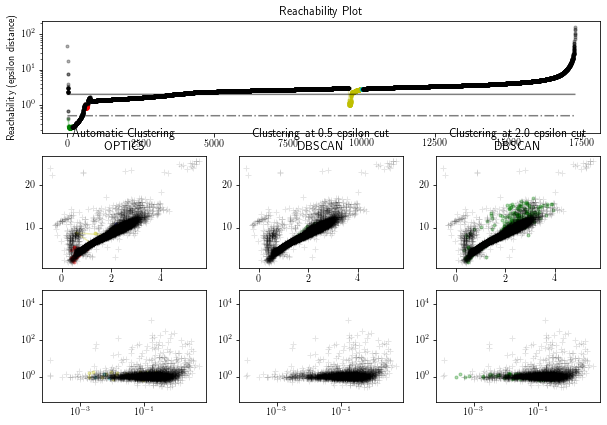

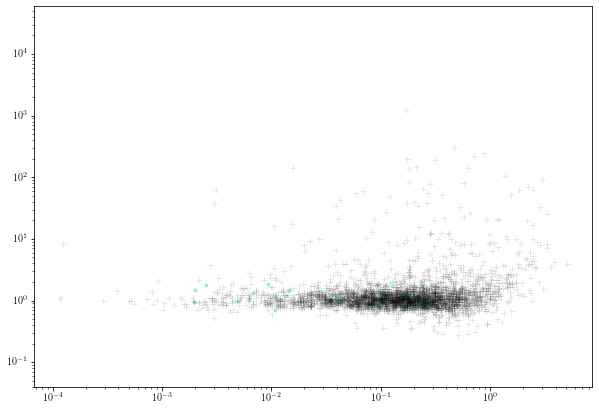

In [147]:

# clust = OPTICS(min_samples=10, xi=0.0, min_cluster_size=100)

clust = OPTICS(
    min_samples=50,
    max_eps=np.inf,
    metric='minkowski',
    p=2,
    metric_params=None,
    cluster_method='xi',
    eps=None,
    xi=0.0,
    predecessor_correction=True,
    min_cluster_size=50,
    algorithm='auto',
    leaf_size=30,
    memory=None,
    n_jobs=None,
)

x_index1 = selection_colnames.index('bp_rp')
y_index1 = selection_colnames.index('M_G')

x_index2 = selection_colnames.index('ZTF_r_P')
y_index2 = selection_colnames.index('ZTF_r_Amp')

# Run the fit
# clust.fit(X)
clust.fit(X_scaled)

labels_050 = cluster_optics_dbscan(
    reachability=clust.reachability_,
    core_distances=clust.core_distances_,
    ordering=clust.ordering_,
    eps=0.5,
)
labels_200 = cluster_optics_dbscan(
    reachability=clust.reachability_,
    core_distances=clust.core_distances_,
    ordering=clust.ordering_,
    eps=2,
)

space = np.arange(len(X_scaled))
reachability = clust.reachability_[clust.ordering_]
labels = clust.labels_[clust.ordering_]

plt.figure(figsize=(10, 7))
G = gridspec.GridSpec(3, 3)
ax1 = plt.subplot(G[0, :])
ax2 = plt.subplot(G[1, 0])
ax3 = plt.subplot(G[1, 1])
ax4 = plt.subplot(G[1, 2])

ax5 = plt.subplot(G[2, 0])
ax6 = plt.subplot(G[2, 1])
ax7 = plt.subplot(G[2, 2])

# Reachability plot
colors = ["g", "r", "b", "y", "c", "orange"]
for klass, color in zip(range(0, 5), colors):
    Xk = space[labels == klass]
    Rk = reachability[labels == klass]
    ax1.plot(Xk, Rk, color=color, marker=".", alpha=0.3)
ax1.plot(space[labels == -1], reachability[labels == -1], "k.", alpha=0.3)
ax1.plot(space, np.full_like(space, 2.0, dtype=float), "k-", alpha=0.5)
ax1.plot(space, np.full_like(space, 0.5, dtype=float), "k-.", alpha=0.5)
ax1.set_ylabel("Reachability (epsilon distance)")
ax1.set_title("Reachability Plot")

ax1.set_yscale('log')

# OPTICS
for klass, color in zip(range(0, 5), colors):
    Xk = X[clust.labels_ == klass]
    ax2.plot(Xk[:, x_index1], Xk[:, y_index1], color=color, marker=".", alpha=0.3)
ax2.plot(X[clust.labels_ == -1, x_index1], X[clust.labels_ == -1, y_index1], "k+", alpha=0.1)
ax2.set_title("Automatic Clustering\nOPTICS")

# DBSCAN at 0.5
colors = ["g", "greenyellow", "olive", "r", "b", "c"]
for klass, color in zip(range(0, 6), colors):
    Xk = X[labels_050 == klass]
    ax3.plot(Xk[:, x_index1], Xk[:, y_index1], color, alpha=0.3, marker=".")
ax3.plot(X[labels_050 == -1, x_index1], X[labels_050 == -1, y_index1], "k+", alpha=0.1)
ax3.set_title("Clustering at 0.5 epsilon cut\nDBSCAN")

# DBSCAN at 2.
colors = ["g.", "m.", "y.", "c."]
for klass, color in zip(range(0, 4), colors):
    Xk = X[labels_200 == klass]
    ax4.plot(Xk[:, x_index1], Xk[:, y_index1], color, alpha=0.3)
ax4.plot(X[labels_200 == -1, x_index1], X[labels_200 == -1, y_index1], "k+", alpha=0.1)
ax4.set_title("Clustering at 2.0 epsilon cut\nDBSCAN")





# OPTICS
colors = ["g.", "r.", "b.", "y.", "c."]
for klass, color in zip(range(0, 5), colors):
    Xk = X[clust.labels_ == klass]
    ax5.plot(Xk[:, x_index2], Xk[:, y_index2], color, alpha=0.3)
ax5.plot(X[clust.labels_ == -1, x_index2], X[clust.labels_ == -1, y_index2], "k+", alpha=0.1)
# ax5.set_title("Automatic Clustering\nOPTICS")

# DBSCAN at 0.5
colors = ["g", "greenyellow", "olive", "r", "b", "c"]
for klass, color in zip(range(0, 6), colors):
    Xk = X[labels_050 == klass]
    ax6.plot(Xk[:, x_index2], Xk[:, y_index2], color, alpha=0.3, marker=".")
ax6.plot(X[labels_050 == -1, x_index2], X[labels_050 == -1, y_index2], "k+", alpha=0.1)
# ax6.set_title("Clustering at 0.5 epsilon cut\nDBSCAN")

# DBSCAN at 2.
colors = ["g.", "m.", "y.", "c."]
for klass, color in zip(range(0, 4), colors):
    Xk = X[labels_200 == klass]
    ax7.plot(Xk[:, x_index2], Xk[:, y_index2], color, alpha=0.3)
ax7.plot(X[labels_200 == -1, x_index2], X[labels_200 == -1, y_index2], "k+", alpha=0.1)
# ax7.set_title("Clustering at 2.0 epsilon cut\nDBSCAN")

ax5.set_xscale('log')
ax6.set_xscale('log')
ax7.set_xscale('log')

ax5.set_yscale('log')
ax6.set_yscale('log')
ax7.set_yscale('log')





plt.figure(figsize=(10, 7))
ax = plt.gca()

# colors = ["g.", "r.", "b.", "y.", "c."]
for klass, color in zip(range(0, 6), colors):
    Xk = X[clust.labels_ == klass]
    ax.plot(Xk[:, x_index2], Xk[:, y_index2], color, alpha=0.3)
ax.plot(X[clust.labels_ == -1, x_index2], X[clust.labels_ == -1, y_index2], "k+", alpha=0.1)

ax.set_xscale('log')
ax.set_yscale('log')